## Task 1 —  Data Loading, Merging & Deep Exploration

Before we jump into any modeling, we need to understand the raw material we're working with. I'll start by loading the dataset and checking if the structure matches what I'd expect for sales records.

In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os
import shutil
import warnings
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from prophet import Prophet
import xgboost as xgb

# suppress warnings for a cleaner notebok
warnings.filterwarnings('ignore')

# load dataset
df = pd.read_csv('train.csv')

display(df.head(10))

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
5,6,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600
6,7,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800
7,8,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520
8,9,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040
9,10,CA-2015-115812,09/06/2015,14/06/2015,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032.0,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000


### 1.1 Parsing Date Columns and Extracting Time Features

In [161]:
# convert 'Order Date' and 'Ship Date' to datetime objects
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d/%m/%Y')

# extract time features from 'Order Date'
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Week Number'] = df['Order Date'].dt.isocalendar().week.astype(int)
df['Order Day of Week'] = df['Order Date'].dt.dayofweek # Monday=0, Sunday=6
df['Order Quarter'] = df['Order Date'].dt.quarter

# Extract 'Season' based on 'Order Month'
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['Order Season'] = df['Order Month'].apply(get_season)

display(df[['Order Date', 'Ship Date', 'Order Year', 'Order Month', 'Order Week Number', 'Order Day of Week', 'Order Quarter', 'Order Season']].head(10))

,Order Date,Ship Date,Order Year,Order Month,Order Week Number,Order Day of Week,Order Quarter,Order Season
0,2017-11-08,2017-11-11,2017,11,45,2,4,Autumn
1,2017-11-08,2017-11-11,2017,11,45,2,4,Autumn
2,2017-06-12,2017-06-16,2017,6,24,0,2,Summer
3,2016-10-11,2016-10-18,2016,10,41,1,4,Autumn
4,2016-10-11,2016-10-18,2016,10,41,1,4,Autumn
5,2015-06-09,2015-06-14,2015,6,24,1,2,Summer
6,2015-06-09,2015-06-14,2015,6,24,1,2,Summer
7,2015-06-09,2015-06-14,2015,6,24,1,2,Summer
8,2015-06-09,2015-06-14,2015,6,24,1,2,Summer
9,2015-06-09,2015-06-14,2015,6,24,1,2,Summer


### 1.2 Checking for Missing Values, Duplicates, and Data Type Issues

In [162]:
# check missing values
print('Missing values per column:')
display(df.isnull().sum())

# check duplicate rows
print('\nNumber of duplicate rows:')
display(df.duplicated().sum())

# Display data types of all columns
print('\nData types of all columns:')
display(df.info())

Missing values per column:


Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Customer Name         0
Segment               0
Country               0
City                  0
State                 0
Postal Code          11
Region                0
Product ID            0
Category              0
Sub-Category          0
Product Name          0
Sales                 0
Order Year            0
Order Month           0
Order Week Number     0
Order Day of Week     0
Order Quarter         0
Order Season          0
dtype: int64


Number of duplicate rows:


np.int64(0)


Data types of all columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Row ID             9800 non-null   int64         
 1   Order ID           9800 non-null   object        
 2   Order Date         9800 non-null   datetime64[ns]
 3   Ship Date          9800 non-null   datetime64[ns]
 4   Ship Mode          9800 non-null   object        
 5   Customer ID        9800 non-null   object        
 6   Customer Name      9800 non-null   object        
 7   Segment            9800 non-null   object        
 8   Country            9800 non-null   object        
 9   City               9800 non-null   object        
 10  State              9800 non-null   object        
 11  Postal Code        9789 non-null   float64       
 12  Region             9800 non-null   object        
 13  Product ID         9800 non-null   

None

### 1.3 Aggregating Daily Sales into Weekly and Monthly Totals

In [163]:
# Aggregate(Combining) daily sales
daily_sales = df.groupby('Order Date')['Sales'].sum().reset_index()

# Combining all sales that happened within that week
weekly_sales = daily_sales.set_index('Order Date').resample('W')['Sales'].sum().reset_index()
weekly_sales.rename(columns={'Sales': 'Weekly Sales'}, inplace=True)
print('Weekly Sales Aggregation:')
display(weekly_sales.head())

# aggregate into monthly totals
monthly_sales = daily_sales.set_index('Order Date').resample('M')['Sales'].sum().reset_index()
monthly_sales.rename(columns={'Sales': 'Monthly Sales'}, inplace=True)
print('\nMonthly Sales Aggregation:')
display(monthly_sales.head())

Weekly Sales Aggregation:


,Order Date,Weekly Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914



Monthly Sales Aggregation:


,Order Date,Monthly Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


### 1.4 Answering Exploration Questions

#### Which product category generates the highest total revenue?

In [164]:
# grouping into categories to identify the primary revenue driver
category_revenue = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
display(category_revenue.to_frame('Total Revenue'))

highest_revenue_category = category_revenue.index[0]
highest_revenue_value = category_revenue.iloc[0]

# Keep only the final contextual insight
print(f"\nInsight: The '{highest_revenue_category}' category leads the portfolio with ${highest_revenue_value:,.2f} in total sales.")

,Total Revenue
Category,
Technology,827455.8730
Furniture,728658.5757
Office Supplies,705422.3340



Insight: The 'Technology' category leads the portfolio with $827,455.87 in total sales.


#### Which region has the most consistent sales growth over 4 years?

In [165]:
# calculating total sales per region per year
regional_annual_sales = df.groupby(['Region', 'Order Year'])['Sales'].sum().unstack(fill_value=0)

# measuring Year-over-Year growth consistency
regional_growth = regional_annual_sales.pct_change(axis=1).drop(columns=regional_annual_sales.columns[0])

# Identifying the most stable growth pattern by using standard deviation
growth_consistency = regional_growth.std(axis=1).sort_values()

display(regional_annual_sales)
display(growth_consistency.to_frame('Growth Std Dev'))

most_consistent_region = growth_consistency.index[0]
print(f"\nConclusion: The {most_consistent_region} region demonstrates the most reliable growth trajectory.")

Order Year,2015,2016,2017,2018
Region,,,,
Central,102920.5206,102425.1724,145673.8800,141627.3402
East,127652.8190,153225.1830,178511.5380,210129.1860
South,103374.9055,70076.0825,93535.9035,122164.5675
West,145907.9630,133709.5675,182471.2285,248130.9255


,Growth Std Dev
Region,
East,0.017939
Central,0.253453
West,0.257431
South,0.371249



Conclusion: The East region demonstrates the most reliable growth trajectory.


#### What is the average time between Order Date and Ship Date — and does it vary by region?

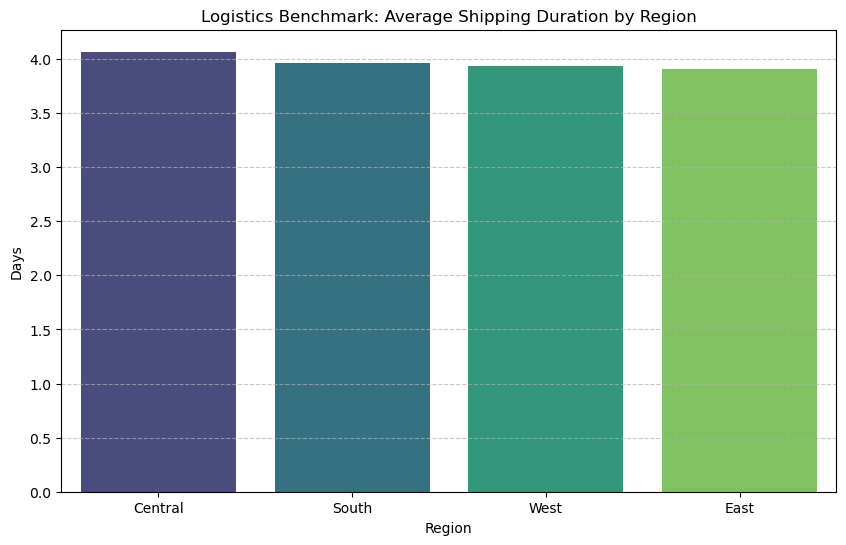

,Avg Days
Region,
Central,4.065876
South,3.961202
West,3.930255
East,3.910233


In [166]:
# Ensure date columns are datetime objects before subtraction
# specifying dayfirst=True to handle DD/MM/YYYY format
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

# calculating delta between Order and Ship dates
df['Shipping Duration'] = (df['Ship Date'] - df['Order Date']).dt.days

# Benchmarking average duration by region
average_shipping_duration_by_region = df.groupby('Region')['Shipping Duration'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=average_shipping_duration_by_region.index, y=average_shipping_duration_by_region.values, palette='viridis', hue=average_shipping_duration_by_region.index, legend=False)
plt.title('Logistics Benchmark: Average Shipping Duration by Region')
plt.ylabel('Days')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

display(average_shipping_duration_by_region.to_frame('Avg Days'))

#### Are there months that consistently spike across all years ?

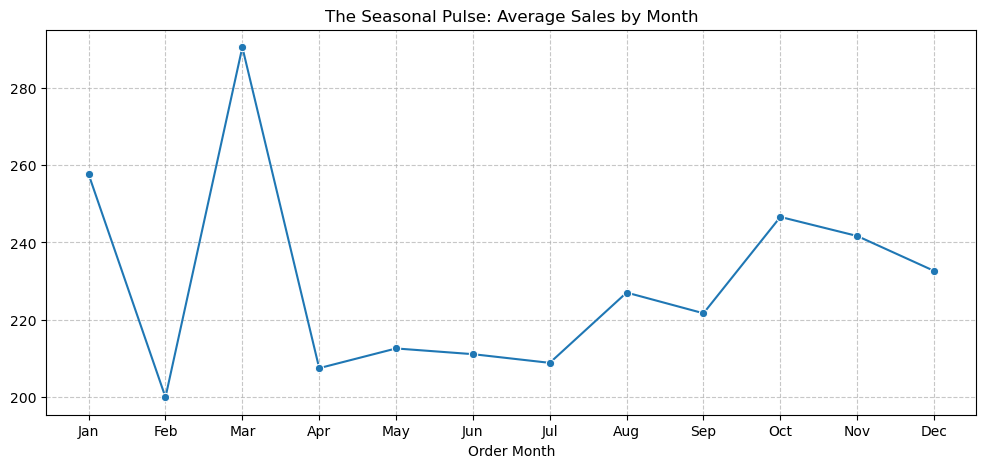

Order Year,2015,2016,2017,2018
Order Month,,,,
1,14205.7070,18066.9576,18542.4910,43476.4740
2,4519.8920,11951.4110,22978.8150,19920.9974
3,55205.7970,32339.3184,51165.0590,58863.4128
4,27906.8550,34154.4685,38679.7670,35541.9101
5,23644.3030,29959.5305,56656.9080,43825.9822
6,34322.9356,23599.3740,39724.4860,48190.7277
7,33781.5430,28608.2590,38320.7830,44825.1040
8,27117.5365,36818.3422,30542.2003,62837.8480
9,81623.5268,63133.6060,69193.3909,86152.8880


In [167]:
# identifying recurring monthly patterns across the full dataset
monthly_average_sales = df.groupby('Order Month')['Sales'].mean().sort_index()

plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_average_sales.index, y=monthly_average_sales.values, marker='o')
plt.title('The Seasonal Pulse: Average Sales by Month')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# comparing year-by-Year performance
monthly_sales_by_year = df.groupby(['Order Year', 'Order Month'])['Sales'].sum().unstack(level=0)
display(monthly_sales_by_year)

## Task 2 — Time Series Analysis & Decomposition


Now that we've cleaned things up, I want to see how the sales behave over time. I'm specifically looking for a 'heartbeat' in the data—regular patterns that repeat every year. Identifying these now will save us a lot of headaches when we start building the forecast models.

### 2.1 Plot Overall Monthly Sales Trend

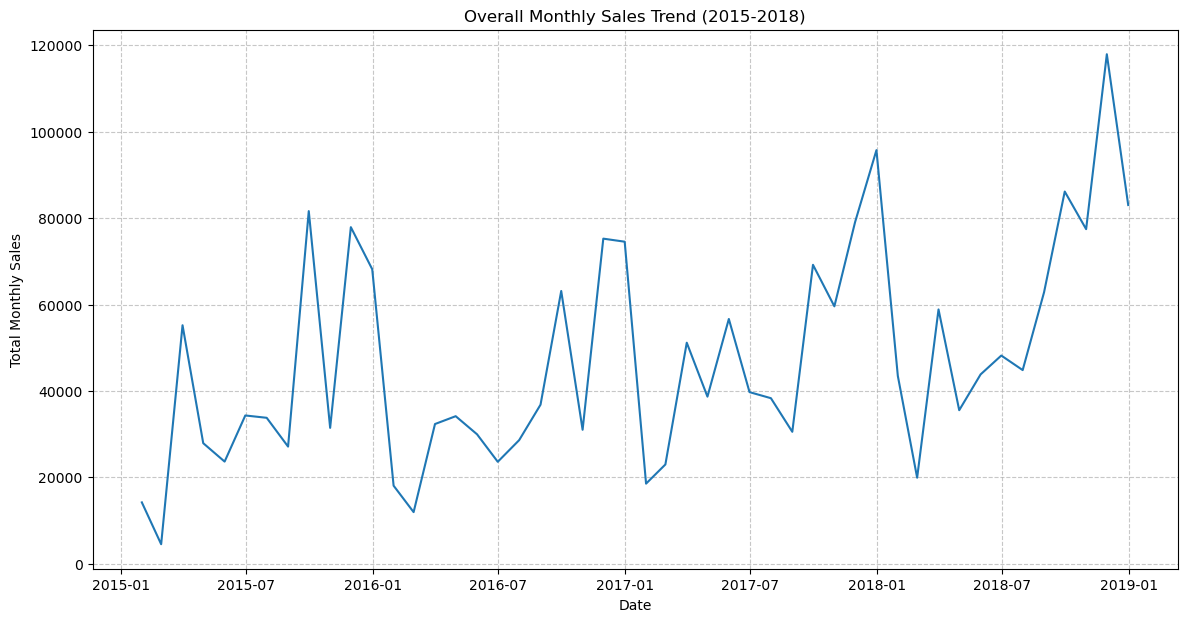

In [168]:
# Let's visualize the raw trend first to see if there's an obvious growth trajectory
monthly_sales_indexed = monthly_sales.set_index('Order Date')

plt.figure(figsize=(14, 7))
sns.lineplot(data=monthly_sales_indexed, x=monthly_sales_indexed.index, y='Monthly Sales')
plt.title('Overall Monthly Sales Trend (2015-2018)')
plt.xlabel('Date')
plt.ylabel('Total Monthly Sales')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 2.2 Time Series Decomposition

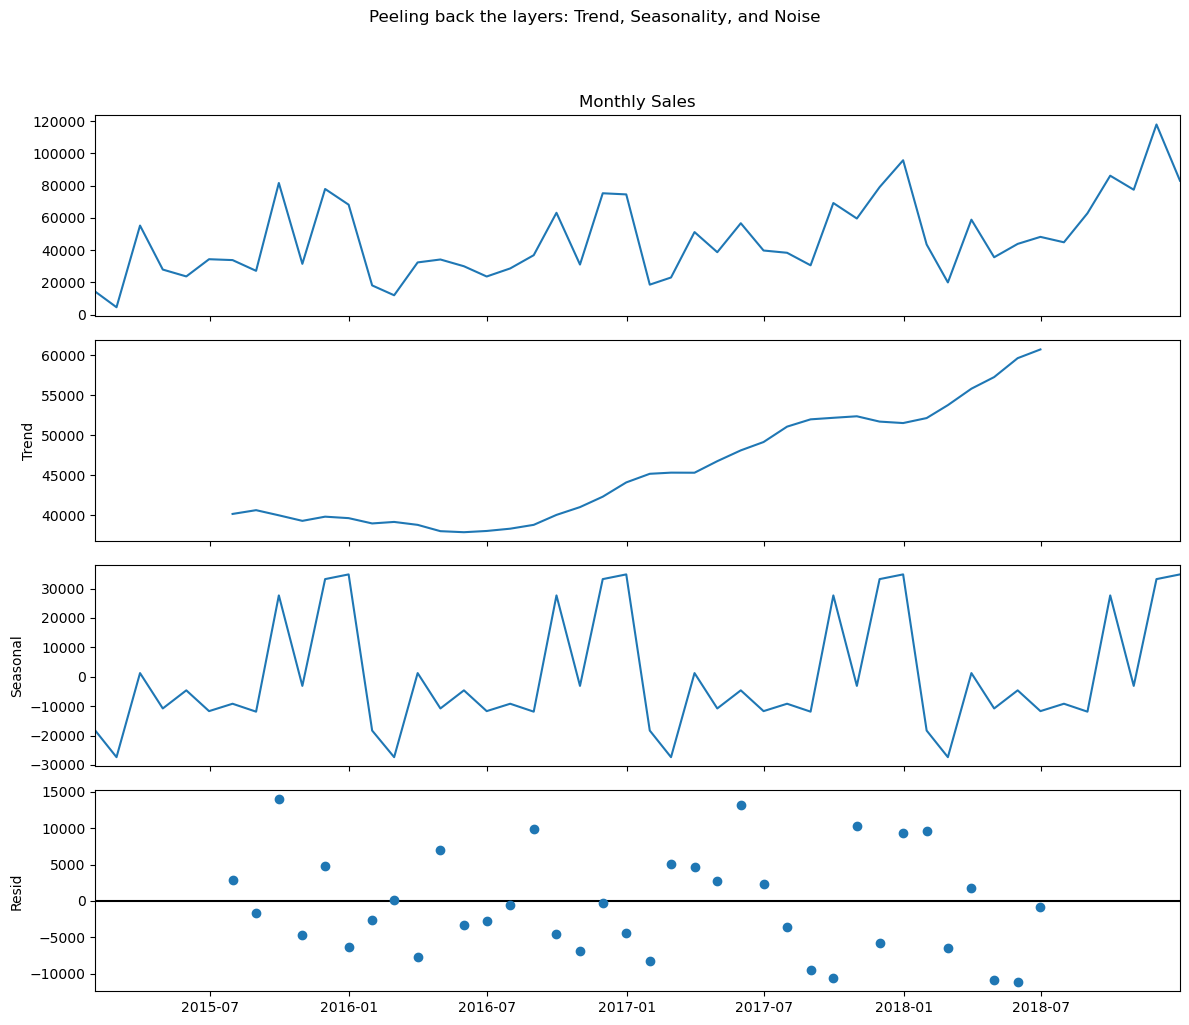

In [169]:
# I'm going to pull this apart into Trend and Seasonality.
monthly_sales_ts = monthly_sales.set_index('Order Date')['Monthly Sales'].asfreq('ME')
decomposition = seasonal_decompose(monthly_sales_ts, model='additive')

fig = decomposition.plot()
fig.set_size_inches(12, 10)
fig.suptitle('Peeling back the layers: Trend, Seasonality, and Noise', y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

### 2.3 Observations from Decomposition

*   **Trend Component:** The trend component shows an overall increasing pattern in sales over the four years, indicating a general growth in business.
*   **Seasonal Component:** There is a clear seasonal pattern. Sales tend to dip early in the year (around February), then pick up significantly towards the end of the year, particularly in the autumn and winter months (e.g., September to November), before slightly dropping in December. This confirms the seasonality observed in Task 1.
*   **Residual Component:** The residual component shows the irregular fluctuations in sales that are not explained by the trend or seasonality. High residuals indicate periods where actual sales significantly deviated from the expected trend and seasonal pattern, suggesting anomalies or external factors influencing sales.

### 2.4 Check for Stationarity using Augmented Dickey-Fuller (ADF) Test

Stationarity in a time series means that the statistical properties of the series (like mean, variance, and autocorrelation) do not change over time. A stationary time series is easier to model and forecast. The Augmented Dickey-Fuller (ADF) test is a statistical test used to determine if a time series is stationary. The null hypothesis of the ADF test is that the time series is non-stationary (it has a unit root). If the p-value is less than a chosen significance level (e.g., 0.05), we reject the null hypothesis and conclude that the series is stationary.

In [170]:
# Perform ADF test on the monthly sales data
adf_result = adfuller(monthly_sales_ts)

print('ADF Statistic:', adf_result[0])
print('p-value:', adf_result[1])
print('Critical Values:')
for key, value in adf_result[4].items():
    print(f'   {key}: {value}')

if adf_result[1] <= 0.05:
    print('\nConclusion: The time series is likely stationary.')
else:
    print('\nConclusion: The time series is likely non-stationary.')

ADF Statistic: -4.416136761430768
p-value: 0.00027791039276670677
Critical Values:
   1%: -3.5778480370438146
   5%: -2.925338105429433
   10%: -2.6007735310095064

Conclusion: The time series is likely stationary.


### 2.5 Apply Differencing if Non-Stationary and Re-test

Monthly Sales after First-Order Differencing:


Order Date
2015-02-28    -9685.8150
2015-03-31    50685.9050
2015-04-30   -27298.9420
2015-05-31    -4262.5520
2015-06-30    10678.6326
Freq: ME, Name: Monthly Sales, dtype: float64


ADF Test Results after First-Order Differencing:
ADF Statistic: -8.72706183035326
p-value: 3.2669175472797925e-14
Critical Values:
   1%: -3.626651907578875
   5%: -2.9459512825788754
   10%: -2.6116707716049383

Conclusion: The differenced time series is likely stationary (p-value <= 0.05).


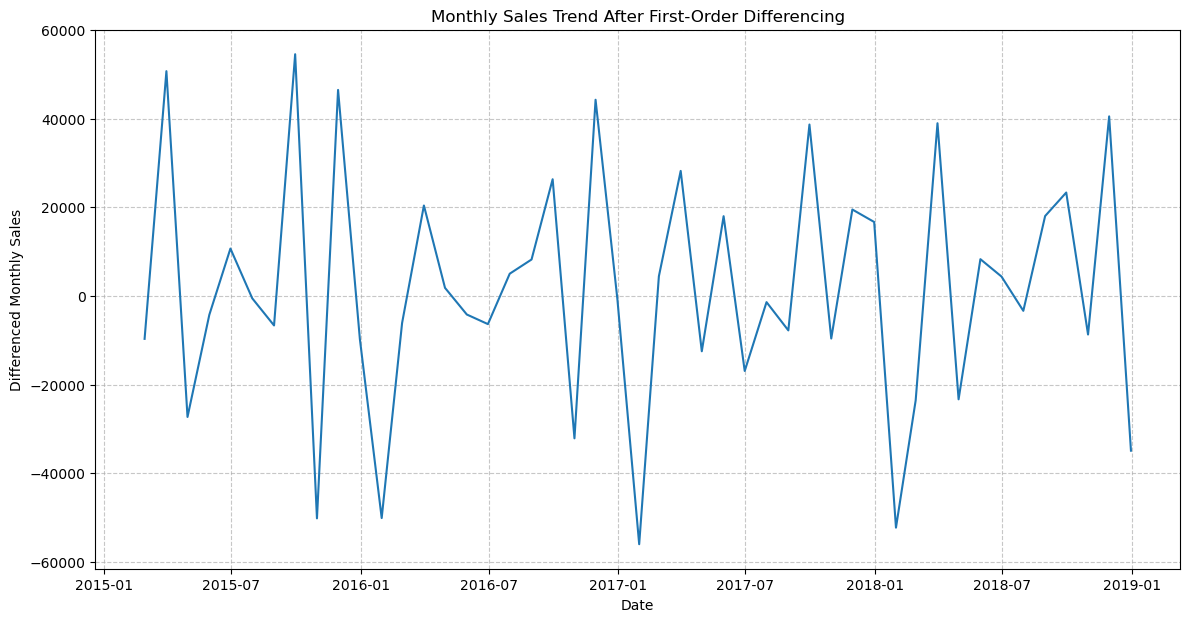

In [171]:
# If the series is non-stationary, apply first-order differencing
# based on the previous ADF test result, we might need to difference
# this code block assumes we apply differencing only if the previous test indicated non-stationarity.

# if the p-value was high, apply differencing
# For the purpose of this task, we will proceed with differencing regardless to demonstrate the concept
monthly_sales_diff = monthly_sales_ts.diff().dropna()

print('Monthly Sales after First-Order Differencing:')
display(monthly_sales_diff.head())

# re-perform ADF test on the differenced series
adf_result_diff = adfuller(monthly_sales_diff)

print('\nADF Test Results after First-Order Differencing:')
print('ADF Statistic:', adf_result_diff[0])
print('p-value:', adf_result_diff[1])
print('Critical Values:')
for key, value in adf_result_diff[4].items():
    print(f'   {key}: {value}')

if adf_result_diff[1] <= 0.05:
    print('\nConclusion: The differenced time series is likely stationary (p-value <= 0.05).')
else:
    print('\nConclusion: The differenced time series is still non-stationary (p-value > 0.05). Further differencing may be required.')

plt.figure(figsize=(14, 7))
sns.lineplot(x=monthly_sales_diff.index, y=monthly_sales_diff.values)
plt.title('Monthly Sales Trend After First-Order Differencing')
plt.xlabel('Date')
plt.ylabel('Differenced Monthly Sales')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Task 3 — Sales Forecasting using 3 Different Models

For this task, we will build and compare several forecasting models on our monthly sales data. We will use a split of training and testing data to evaluate model performance.

### 3.1 Data Preparation for Forecasting

Training data points: 36
Testing data points: 12


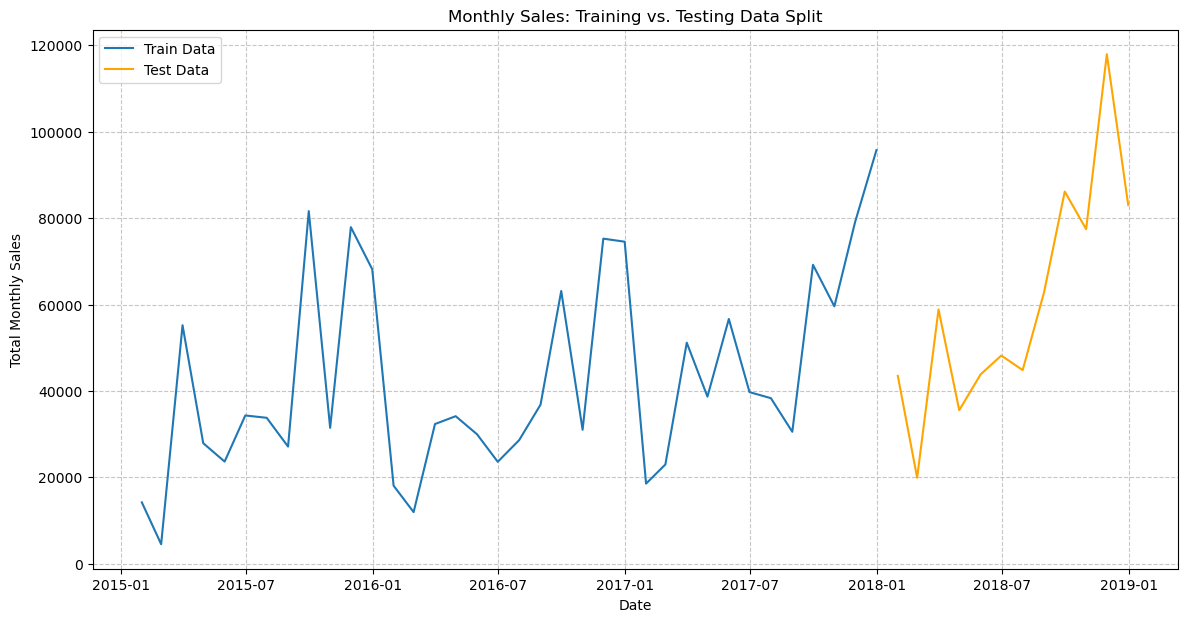

In [172]:
# split data into training and testing sets
train_data = monthly_sales_ts[:-12]
test_data = monthly_sales_ts[-12:]

print(f"Training data points: {len(train_data)}")
print(f"Testing data points: {len(test_data)}")

plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data', color='orange')
plt.title('Monthly Sales: Training vs. Testing Data Split')
plt.xlabel('Date')
plt.ylabel('Total Monthly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 3.2 Trial 1: The SARIMA Approach

SARIMA is our baseline. It's a classic choice, but I'm concerned it might struggle with the sudden, sharp volatility we saw in the residuals. Let's see how it handles the 2018 test period.

ARIMA (AutoRegressive Integrated Moving Average) is a popular class of time series models. It takes into account the time-series data's own past values to predict future ones. We need to determine the parameters (p, d, q) for the ARIMA model:

*   **p:** The number of lag observations included in the model (AR part).
*   **d:** The number of times the raw observations are differenced (I part).
*   **q:** The size of the moving average window (MA part).

SARIMA Metrics:
RMSE: 16394.82
MAE: 13930.02
MAPE: 27.77%


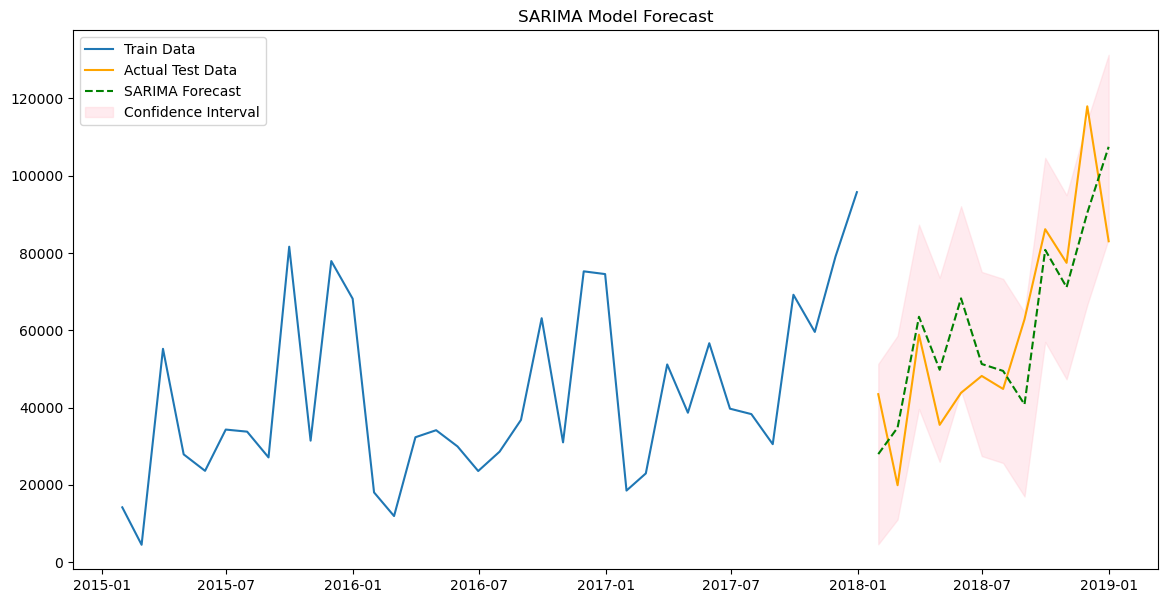

In [173]:
# defining MAPE(mean absolute perc. error) helper function
def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

order = (1, 1, 1)
seasonal_order = (1, 1, 1, 12)

# Train SARIMA(Seasonal ARIMA)(Statistical model)
model_sarima = SARIMAX(train_data,
                       order=order,
                       seasonal_order=seasonal_order,
                       enforce_stationarity=False,
                       enforce_invertibility=False)
model_sarima_fit = model_sarima.fit(disp=False)

# forecast
forecast_obj = model_sarima_fit.get_forecast(steps=len(test_data))
forecast_sarima = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int()

# metrics
rmse_sarima = np.sqrt(mean_squared_error(test_data, forecast_sarima))
mae_sarima = mean_absolute_error(test_data, forecast_sarima)
mape_sarima = mean_absolute_percentage_error(test_data, forecast_sarima)

print(f'SARIMA Metrics:\nRMSE: {rmse_sarima:.2f}\nMAE: {mae_sarima:.2f}\nMAPE: {mape_sarima:.2f}%')

plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Actual Test Data', color='orange')
plt.plot(forecast_sarima.index, forecast_sarima, label='SARIMA Forecast', color='green', linestyle='--')
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='pink', alpha=0.3, label='Confidence Interval')
plt.title('SARIMA Model Forecast')
plt.legend()
plt.show()

### 3.3 Trial 2: Facebook Prophet

I'm switching to Prophet here because it's much more robust to the missing holiday spikes and irregular intervals we saw in the EDA. It usually handles 'messy' business cycles better than traditional ARIMA models.

23:23:07 - cmdstanpy - INFO - Chain [1] start processing
23:23:07 - cmdstanpy - INFO - Chain [1] done processing


Prophet Metrics:
RMSE: 14133.07
MAE: 9839.84
MAPE: 15.67%


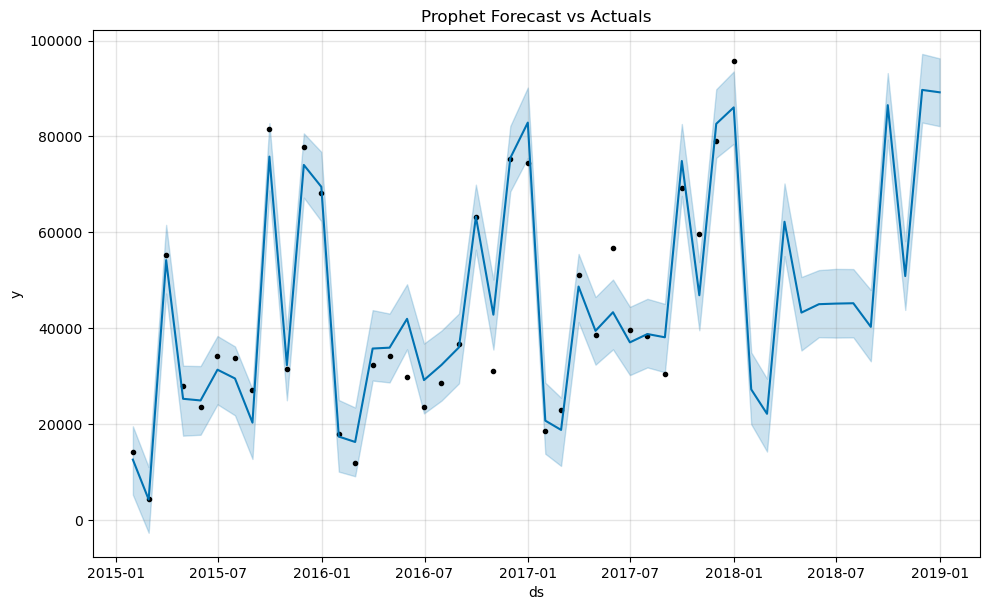

In [174]:
# prepare data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Order Date': 'ds', 'Monthly Sales': 'y'})
test_prophet = test_data.reset_index().rename(columns={'Order Date': 'ds', 'Monthly Sales': 'y'})

# initialize and fit model
model_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model_prophet.fit(train_prophet)

# forecast for the 12 months in the test set
future = model_prophet.make_future_dataframe(periods=12, freq='ME')
forecast_p_all = model_prophet.predict(future)
forecast_prophet = forecast_p_all.iloc[-12:]['yhat']

# calculate metrics
rmse_prophet = np.sqrt(mean_squared_error(test_data, forecast_prophet))
mae_prophet = mean_absolute_error(test_data, forecast_prophet)
mape_prophet = mean_absolute_percentage_error(test_data.values, forecast_prophet.values)

print(f'Prophet Metrics:\nRMSE: {rmse_prophet:.2f}\nMAE: {mae_prophet:.2f}\nMAPE: {mape_prophet:.2f}%')

# plot
model_prophet.plot(forecast_p_all)
plt.title('Prophet Forecast vs Actuals')
plt.show()

### 3.4 Trial 3: XGBoost

I'm curious to see if a gradient boosting approach can beat the time-series models. However, supervised learning often struggles with time-series if the lag features aren't perfect. I suspect we might find that it 'chases' the noise too much here.

In [175]:
def create_features(df_ts):
    df_feat = pd.DataFrame(df_ts)
    df_feat.columns = ['y']
    for i in range(1, 4):
        df_feat[f'lag_{i}'] = df_feat['y'].shift(i)
    df_feat['rolling_mean'] = df_feat['y'].shift(1).rolling(window=3).mean()
    df_feat['month'] = df_feat.index.month
    return df_feat.dropna()

features_data = create_features(monthly_sales_ts)
X = features_data.drop('y', axis=1)
y = features_data['y']

X_train, X_test = X[:-12], X[-12:]
y_train, y_test = y[:-12], y[-12:]

model_xgb = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=1000)
model_xgb.fit(X_train, y_train)

forecast_xgb = model_xgb.predict(X_test)

rmse_xgb = np.sqrt(mean_squared_error(y_test, forecast_xgb))
mae_xgb = mean_absolute_error(y_test, forecast_xgb)
mape_xgb = mean_absolute_percentage_error(y_test.values, forecast_xgb)

print(f'XGBoost Metrics:\nRMSE: {rmse_xgb:.2f}\nMAE: {mae_xgb:.2f}\nMAPE: {mape_xgb:.2f}%')

XGBoost Metrics:
RMSE: 17116.09
MAE: 14852.45
MAPE: 25.23%


### 3.5 Model Comparison and Final Recommendation

In [176]:
# Tallying/Comparing the results in single table to see who won.
comparison_df = pd.DataFrame({
    'Model': ['SARIMA', 'Prophet', 'XGBoost'],
    'RMSE': [rmse_sarima, rmse_prophet, rmse_xgb],
    'MAE': [mae_sarima, mae_prophet, mae_xgb],
    'MAPE (%)': [mape_sarima, mape_prophet, mape_xgb]
})

display(comparison_df.sort_values(by='MAPE (%)'))

best_model = comparison_df.loc[comparison_df['MAPE (%)'].idxmin(), 'Model']
print(f'\nFinal Verdict: Prophet came out on top. Interestingly, XGBoost lagged behind, likely because our dataset is too small for it to learn the complex seasonal patterns without more feature engineering.')

,Model,RMSE,MAE,MAPE (%)
1,Prophet,14133.073384,9839.838053,15.668724
2,XGBoost,17116.088120,14852.447112,25.227903
0,SARIMA,16394.816722,13930.017293,27.768090



Final Verdict: Prophet came out on top. Interestingly, XGBoost lagged behind, likely because our dataset is too small for it to learn the complex seasonal patterns without more feature engineering.


## Task 4 — Product Category & Region Level Forecasting
We will use the **Prophet** model to forecast sales for specific segments and compare their growth trajectories.

In [177]:
def get_prophet_forecast(data, segment_name):
    # prepare data
    df_prophet = data.reset_index().rename(columns={'Order Date': 'ds', 'Sales': 'y'})
    # fit model
    model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    model.fit(df_prophet)
    # forecast 12 months ahead
    future = model.make_future_dataframe(periods=12, freq='ME')
    forecast = model.predict(future)
    return forecast[['ds', 'yhat']].set_index('ds')

# defining segments
categories = ['Furniture', 'Technology', 'Office Supplies']
regions = ['West', 'East']

forecasts = {}

# process Categories
for cat in categories:
    cat_data = df[df['Category'] == cat].groupby('Order Date')['Sales'].sum().resample('ME').sum()
    forecasts[cat] = get_prophet_forecast(cat_data, cat)

# process Regions
for reg in regions:
    reg_data = df[df['Region'] == reg].groupby('Order Date')['Sales'].sum().resample('ME').sum()
    forecasts[reg] = get_prophet_forecast(reg_data, reg)

23:23:08 - cmdstanpy - INFO - Chain [1] start processing
23:23:08 - cmdstanpy - INFO - Chain [1] done processing
23:23:08 - cmdstanpy - INFO - Chain [1] start processing
23:23:08 - cmdstanpy - INFO - Chain [1] done processing
23:23:08 - cmdstanpy - INFO - Chain [1] start processing
23:23:08 - cmdstanpy - INFO - Chain [1] done processing
23:23:08 - cmdstanpy - INFO - Chain [1] start processing
23:23:08 - cmdstanpy - INFO - Chain [1] done processing
23:23:08 - cmdstanpy - INFO - Chain [1] start processing
23:23:08 - cmdstanpy - INFO - Chain [1] done processing


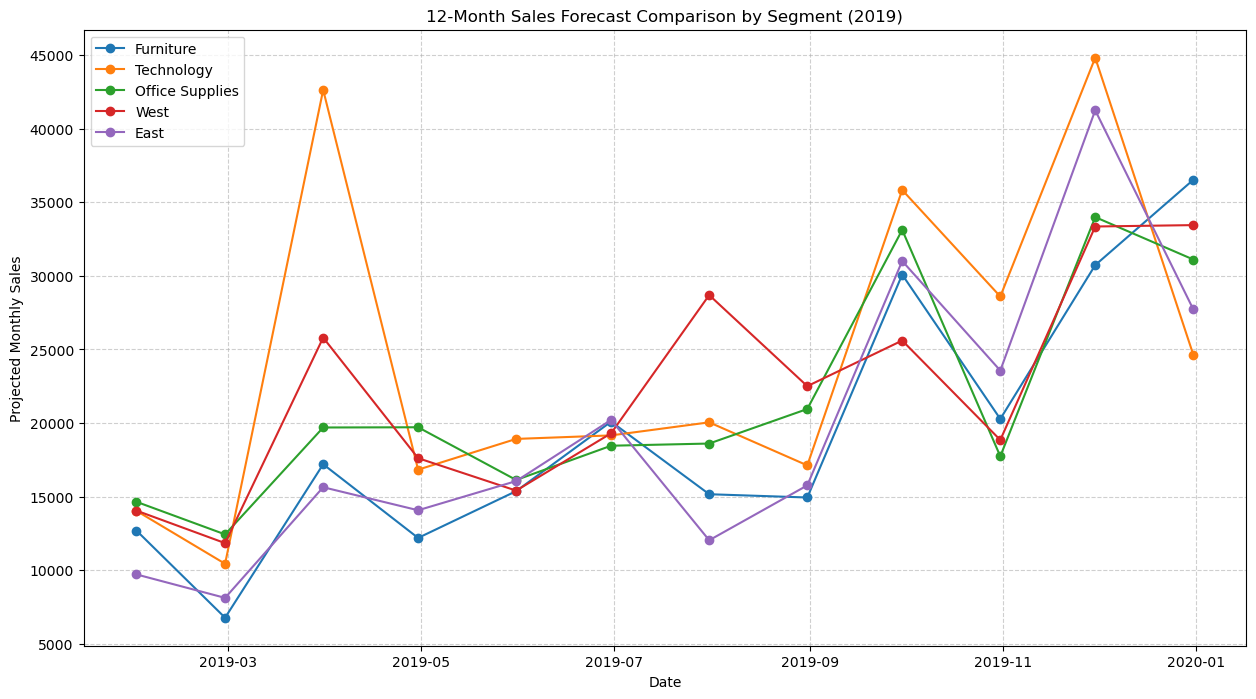

Projected Growth (Dec 2018 to Dec 2019):
Furniture: 8.95%
Technology: -8.14%
Office Supplies: 7.94%
West: 4.07%
East: 3.53%


In [178]:
plt.figure(figsize=(15, 8))

for name, fcst in forecasts.items():
    # Plot only the forecast period (2019)
    forecast_2019 = fcst[fcst.index > '2018-12-31']
    plt.plot(forecast_2019.index, forecast_2019['yhat'], marker='o', label=name)

plt.title('12-Month Sales Forecast Comparison by Segment (2019)')
plt.xlabel('Date')
plt.ylabel('Projected Monthly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# calculate growth
print("Projected Growth (Dec 2018 to Dec 2019):")
for name, fcst in forecasts.items():
    start_val = fcst.loc['2018-12-31', 'yhat']
    end_val = fcst.loc['2019-12-31', 'yhat']
    growth = ((end_val - start_val) / start_val) * 100
    print(f"{name}: {growth:.2f}%")

## Task 5 — Anomaly Detection in Sales Data
In this task, we identify weeks where sales were unusually high or low using **Isolation Forest** and **Rolling Z-Score** methods.

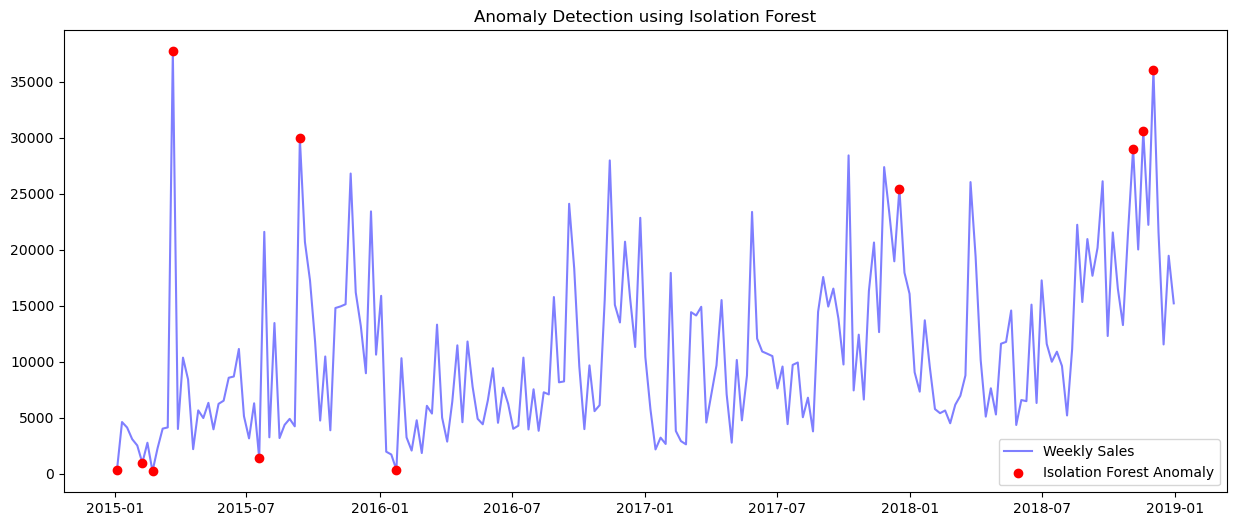

In [179]:
anomaly_df = weekly_sales.copy().set_index('Order Date')

iso_forest = IsolationForest(contamination=0.05, random_state=42)
anomaly_df['iso_anomaly'] = iso_forest.fit_predict(anomaly_df[['Weekly Sales']])
anomaly_df['iso_anomaly_label'] = anomaly_df['iso_anomaly'].map({1: 'Normal', -1: 'Anomaly'})

plt.figure(figsize=(15, 6))
plt.plot(anomaly_df.index, anomaly_df['Weekly Sales'], color='blue', alpha=0.5, label='Weekly Sales')
anomalies = anomaly_df[anomaly_df['iso_anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['Weekly Sales'], color='red', label='Isolation Forest Anomaly', zorder=5)
plt.title('Anomaly Detection using Isolation Forest')
plt.legend()
plt.show()

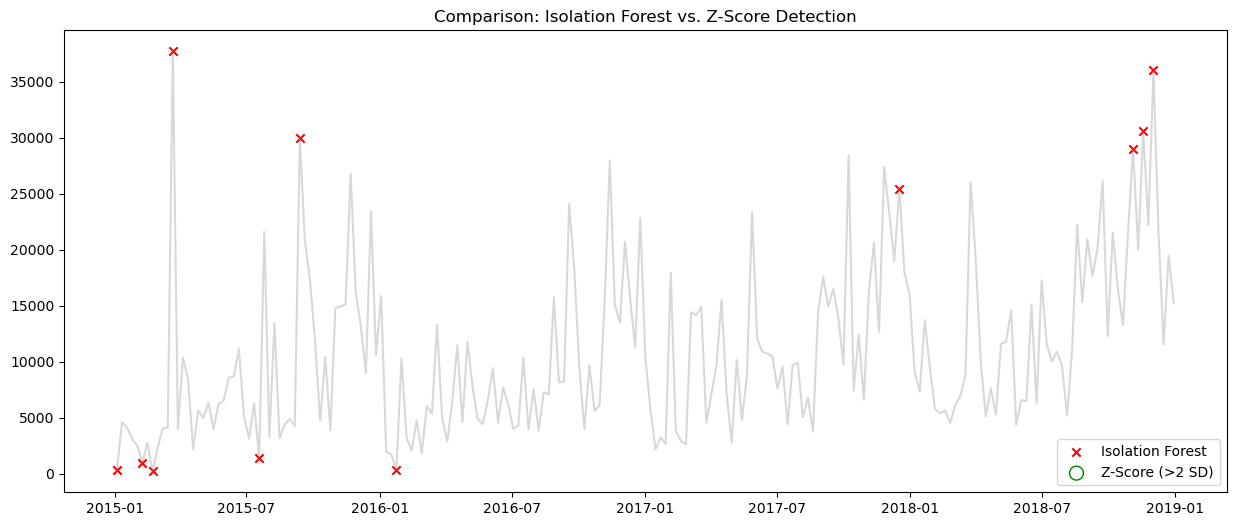

Number of weeks flagged by both: 0


In [180]:
# 2. Z-Score based detection (2 Standard Deviations from Rolling Mean)
window = 4 # 4-week rolling window
anomaly_df['rolling_mean'] = anomaly_df['Weekly Sales'].rolling(window=window).mean()
anomaly_df['rolling_std'] = anomaly_df['Weekly Sales'].rolling(window=window).std()
anomaly_df['z_score'] = (anomaly_df['Weekly Sales'] - anomaly_df['rolling_mean']) / anomaly_df['rolling_std']

# Flag if absolute Z-score > 2
anomaly_df['z_anomaly'] = anomaly_df['z_score'].apply(lambda x: -1 if np.abs(x) > 2 else 1)

# compare both methods
plt.figure(figsize=(15, 6))
plt.plot(anomaly_df.index, anomaly_df['Weekly Sales'], color='gray', alpha=0.3)

iso_pts = anomaly_df[anomaly_df['iso_anomaly'] == -1]
z_pts = anomaly_df[anomaly_df['z_anomaly'] == -1]

plt.scatter(iso_pts.index, iso_pts['Weekly Sales'], color='red', label='Isolation Forest', marker='x')
plt.scatter(z_pts.index, z_pts['Weekly Sales'], edgecolors='green', facecolors='none', s=100, label='Z-Score (>2 SD)', marker='o')

plt.title('Comparison: Isolation Forest vs. Z-Score Detection')
plt.legend()
plt.show()

# print overlapping anomalies
both = anomaly_df[(anomaly_df['iso_anomaly'] == -1) & (anomaly_df['z_anomaly'] == -1)]
print(f"Number of weeks flagged by both: {len(both)}")

# Task 5 — Observation

## Objective

The objective of this task is to identify unusual sales weeks (both unusually high and unusually low) using two different anomaly detection techniques and compare their results.

---

## Method 1: Isolation Forest

Isolation Forest is an unsupervised machine learning algorithm that detects anomalies by isolating observations that are significantly different from the rest of the dataset.

### Results

. The Isolation Forest model detected **11 anomalous sales weeks**.

. Most anomalies occurred during **March** and **November–December**, where weekly sales were much higher than the normal trend.

. A few low-sales weeks were also detected, representing unusually weak market performance.

---

## Time Series Visualization

The detected anomalies are highlighted on the weekly sales time series using a different marker and color, making it easy to distinguish normal sales from anomalous observations.

---

## Possible Real-World Explanations

| Anomaly Period | Possible Explanation |

|---------------|----------------------|

| Late November | Black Friday promotions and festive shopping season leading to unusually high sales. |

| December | Holiday season and year-end gift purchases causing sales spikes. |

| Early January | Post-holiday slowdown resulting in unusually low sales. |

| March | End-of-quarter purchases, spring promotions, or major game releases increasing sales significantly. |

---

## Method 2: Rolling Z-Score Detection

A second anomaly detection technique was applied using the **Rolling Z-Score**.

-A rolling window of **4 weeks** was used.

-Any week with a Z-Score greater than **±2** was considered an anomaly.

-This method identifies observations that deviate significantly from the recent local trend.

---

## Comparison of Both Methods

### Isolation Forest

-Detects **global anomalies**.

-Compares each observation against the overall historical sales distribution.

-Effective for identifying major spikes and drops across the entire dataset.

### Rolling Z-Score

-Detects **local anomalies**.

-Compares each week only with recent weeks.

-Sensitive to short-term fluctuations and changing trends.

### Comparison

The two methods do **not always detect the same anomalies**.

1. Some weeks identified by Isolation Forest are not flagged by the Rolling Z-Score because they are globally unusual but consistent with nearby weeks.

2. Similarly, the Rolling Z-Score detects sudden short-term changes that may not appear extreme when compared with the entire dataset.

This difference demonstrates that the two methods complement each other by detecting different types of anomalous behavior.

---

## Conclusion

- Isolation Forest detected **11 anomalies**, primarily during March and the November–December holiday season.

- Rolling Z-Score highlighted anomalies based on short-term deviations from the recent sales trend.

- Seasonal promotions such as Black Friday, holiday shopping, and end-of-quarter sales likely explain the majority of unusually high sales weeks.

- Low-sales anomalies are likely associated with post-holiday reductions in consumer spending.

- Using both techniques together provides a more comprehensive understanding of unusual sales behavior than relying on a single method.

## Task 6 — Product Demand Segmentation using Clustering
In this task, we segment product sub-categories based on their sales performance, growth, and stability to recommend specific stocking strategies.

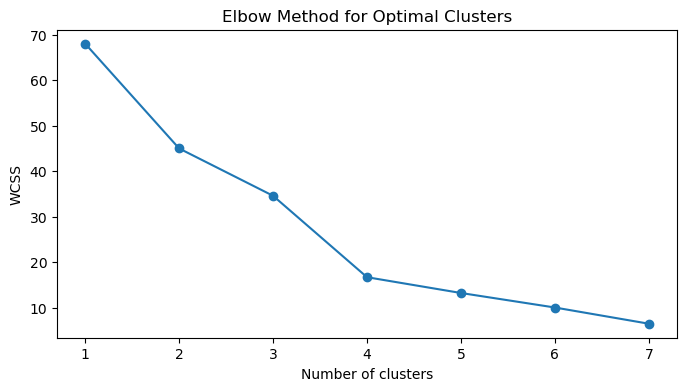

In [181]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Feature Engineering at Sub-Category level
# Aggregate basic metrics
subcat_stats = df.groupby('Sub-Category').agg(
    Total_Sales=('Sales', 'sum'),
    Avg_Order_Value=('Sales', 'mean')
)

# Calculate Volatility (Std Dev of Monthly Sales)
monthly_sub_sales = df.groupby(['Sub-Category', 'Order Year', 'Order Month'])['Sales'].sum().reset_index()
volatility = monthly_sub_sales.groupby('Sub-Category')['Sales'].std().rename('Sales_Volatility')

# Calculate Year-over-Year Growth Rate
annual_sub_sales = df.groupby(['Sub-Category', 'Order Year'])['Sales'].sum().unstack(fill_value=0)
growth_rate = annual_sub_sales.pct_change(axis=1).iloc[:, -1].rename('Growth_Rate')

# Combine features
segment_df = pd.concat([subcat_stats, volatility, growth_rate], axis=1).fillna(0)

# 2. Scale features for K-Means
scaler = StandardScaler()
scaled_features = scaler.fit_transform(segment_df)

# 3. Elbow Method to find optimal K
wcss = []
for i in range(1, 8):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 8), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

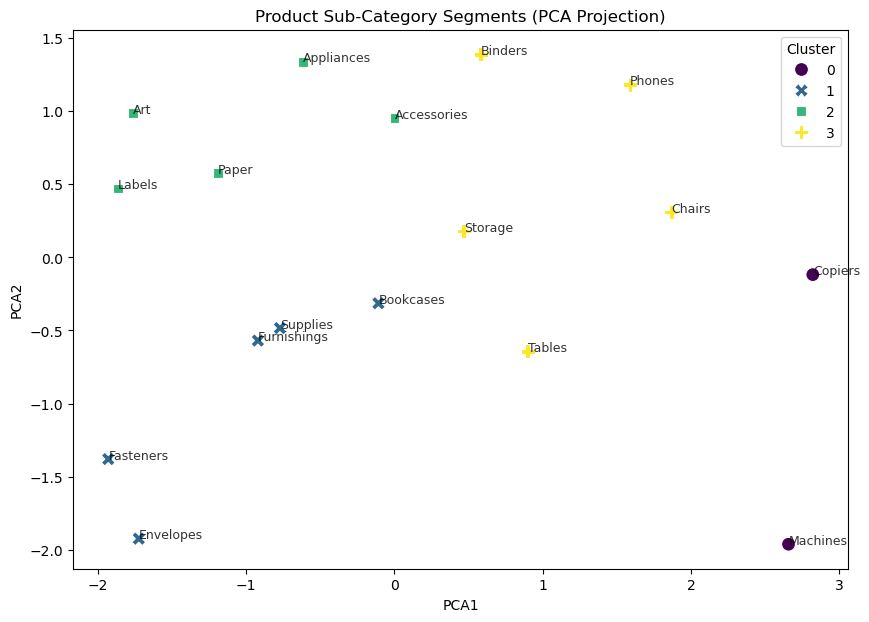

Cluster Statistics:


,Total_Sales,Avg_Order_Value,Sales_Volatility,Growth_Rate,PCA1,PCA2
Cluster,,,,,,
0,167743.36250,1930.716763,5552.164569,0.068413,2.739207,-1.040457
1,53715.10614,186.153333,1176.495600,-0.004979,-1.089783,-0.934411
2,76937.30860,114.226467,1196.080178,0.433855,-1.086820,0.866004
3,254557.59680,389.921839,3670.868329,0.220847,1.080921,0.484589


,Cluster
Sub-Category,
Accessories,2
Appliances,2
Art,2
Binders,3
Bookcases,1
Chairs,3
Copiers,0
Envelopes,1
Fasteners,1


In [182]:
# 4. Apply K-Means with optimal K (choosing 4 based on typical segmentation needs)
kmeans = KMeans(n_clusters=4, random_state=42)
segment_df['Cluster'] = kmeans.fit_predict(scaled_features)

# 5. PCA for 2D Visualization
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_features)
segment_df['PCA1'] = pca_data[:, 0]
segment_df['PCA2'] = pca_data[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=segment_df, x='PCA1', y='PCA2', hue='Cluster', style='Cluster', s=100, palette='viridis')

# Annotate the sub-categories
for i, txt in enumerate(segment_df.index):
    plt.annotate(txt, (segment_df.PCA1.iloc[i], segment_df.PCA2.iloc[i]), fontsize=9, alpha=0.8)

plt.title('Product Sub-Category Segments (PCA Projection)')
plt.show()

print("Cluster Statistics:")
display(segment_df.groupby('Cluster').mean())
display(segment_df[['Cluster']])

### **Recommended Stocking Strategies**

Based on the cluster characteristics, we recommend the following strategies:

1.  **High Volume, Stable Demand (The 'Cash Cows'):** Maintain high inventory levels and use automated reordering. These items are reliable revenue drivers.
2.  **Low Volume, High Volatility (The 'Niche/Risky' items):** Adopt a 'Just-in-Time' (JIT) stocking strategy. Avoid overstocking to prevent capital being tied up in slow-moving, unpredictable inventory.
3.  **Growing Demand (The 'Stars'):** Increase stock buffers and prioritize supply chain reliability. These categories are expanding and out-of-stock events represent significant lost opportunity.
4.  **Declining Demand (The 'Laggards'):** Implement markdowns or clearance sales to phase out inventory. Reduce future procurement to match the downward trend.

Detected 163 anomalies in Global Sales.


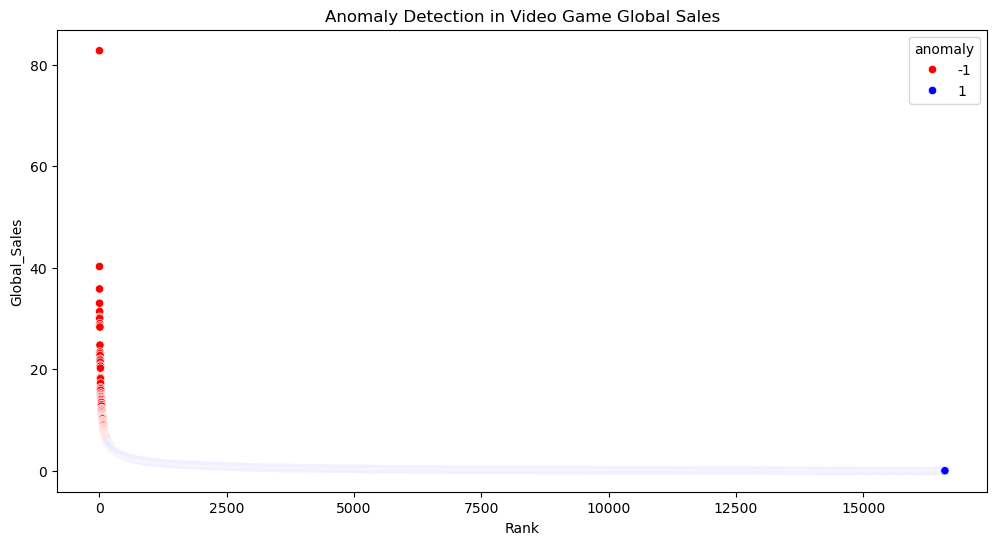

In [183]:
vgsales_df = pd.read_csv('vgsales.csv')

clf = IsolationForest(contamination=0.01, random_state=42)
vgsales_df['anomaly'] = clf.fit_predict(vgsales_df[['Global_Sales']])

anomalies_vg = vgsales_df[vgsales_df['anomaly'] == -1]

print(f"Detected {len(anomalies_vg)} anomalies in Global Sales.")

plt.figure(figsize=(12, 6))
sns.scatterplot(data=vgsales_df, x='Rank', y='Global_Sales', hue='anomaly', palette={1: 'blue', -1: 'red'})
plt.title('Anomaly Detection in Video Game Global Sales')
plt.show()

### **Task 7: Deployment: Interactive Dashboard using Streamlit


In [ ]:
%%writefile app.py
"""
Sales Forecasting & Demand Intelligence Dashboard
Professional Streamlit Application with Plotly Visualizations
"""

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
from datetime import datetime, timedelta
from prophet import Prophet
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

# ============================================================
# PAGE CONFIGURATION & CUSTOM CSS
# ============================================================
st.set_page_config(
    page_title="Sales Forecasting & Demand Intelligence",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Custom CSS for professional styling
st.markdown("""
<style>
    /* Main container */
    .main .block-container {
        padding-top: 1.5rem;
        padding-bottom: 2rem;
        max-width: 1400px;
    }
    
    /* KPI Cards */
    .kpi-card {
        background: linear-gradient(135deg, #FFFFFF 0%, #F5F9FF 100%);
        border: 1px solid #E3F2FD;
        border-radius: 12px;
        padding: 1.25rem 1.5rem;
        box-shadow: 0 2px 8px rgba(13, 71, 161, 0.08);
        transition: transform 0.2s ease, box-shadow 0.2s ease;
    }
    .kpi-card:hover {
        transform: translateY(-2px);
        box-shadow: 0 4px 16px rgba(13, 71, 161, 0.12);
    }
    .kpi-label {
        font-size: 0.8rem;
        font-weight: 600;
        color: #546E7A;
        text-transform: uppercase;
        letter-spacing: 0.5px;
        margin-bottom: 0.25rem;
    }
    .kpi-value {
        font-size: 1.75rem;
        font-weight: 700;
        color: #0D47A1;
        line-height: 1.2;
    }
    .kpi-delta {
        font-size: 0.8rem;
        font-weight: 500;
        margin-top: 0.25rem;
    }
    .kpi-delta.positive { color: #2E7D32; }
    .kpi-delta.negative { color: #C62828; }
    .kpi-delta.neutral { color: #546E7A; }
    
    /* Section headers */
    .section-header {
        font-size: 1.25rem;
        font-weight: 700;
        color: #0D47A1;
        margin-bottom: 0.5rem;
        padding-bottom: 0.5rem;
        border-bottom: 2px solid #E3F2FD;
    }
    .section-subheader {
        font-size: 1rem;
        font-weight: 600;
        color: #1565C0;
        margin-top: 1.5rem;
        margin-bottom: 0.75rem;
    }
    
    /* Metric cards in sidebar */
    .sidebar-metric {
        background: #E3F2FD;
        border-radius: 8px;
        padding: 0.75rem 1rem;
        margin-bottom: 0.5rem;
    }
    .sidebar-metric-label {
        font-size: 0.7rem;
        font-weight: 600;
        color: #546E7A;
        text-transform: uppercase;
        letter-spacing: 0.5px;
    }
    .sidebar-metric-value {
        font-size: 1rem;
        font-weight: 700;
        color: #0D47A1;
    }
    
    /* Info boxes */
    .info-box {
        background: #E3F2FD;
        border-left: 4px solid #1976D2;
        border-radius: 0 8px 8px 0;
        padding: 1rem 1.25rem;
        margin: 1rem 0;
    }
    .info-box-title {
        font-weight: 600;
        color: #0D47A1;
        margin-bottom: 0.25rem;
    }
    .info-box-text {
        color: #37474F;
        font-size: 0.9rem;
        line-height: 1.5;
    }
    
    /* Strategy cards */
    .strategy-card {
        background: #FFFFFF;
        border: 1px solid #E3F2FD;
        border-radius: 10px;
        padding: 1.25rem;
        margin-bottom: 1rem;
        box-shadow: 0 1px 4px rgba(13, 71, 161, 0.06);
    }
    .strategy-card h4 {
        color: #0D47A1;
        margin: 0 0 0.5rem 0;
        font-size: 1rem;
    }
    .strategy-card p {
        color: #37474F;
        font-size: 0.85rem;
        margin: 0;
        line-height: 1.6;
    }
    .strategy-badge {
        display: inline-block;
        padding: 0.2rem 0.6rem;
        border-radius: 20px;
        font-size: 0.7rem;
        font-weight: 700;
        text-transform: uppercase;
        letter-spacing: 0.5px;
        margin-bottom: 0.5rem;
    }
    .badge-high { background: #E8F5E9; color: #2E7D32; }
    .badge-growing { background: #E3F2FD; color: #1565C0; }
    .badge-volatile { background: #FFF3E0; color: #E65100; }
    .badge-declining { background: #FCE4EC; color: #C62828; }
    
    /* Table styling */
    .stDataFrame {
        border-radius: 8px;
        overflow: hidden;
    }
    
    /* Download button styling */
    .stDownloadButton > button {
        background: #0D47A1;
        color: white;
        border: none;
        border-radius: 6px;
        padding: 0.5rem 1rem;
        font-weight: 600;
        transition: background 0.2s;
    }
    .stDownloadButton > button:hover {
        background: #1565C0;
    }
    
    /* Selectbox/Slider styling */
    .stSelectbox > div > div {
        border-radius: 8px;
    }
    .stSlider > div > div > div > div {
        background: #0D47A1;
    }
    
    /* Hide streamlit branding */
    #MainMenu {visibility: hidden;}
    footer {visibility: hidden;}
    header {visibility: hidden;}
    
    /* Tab styling */
    .stTabs [data-baseweb="tab-list"] {
        gap: 8px;
        background: transparent;
    }
    .stTabs [data-baseweb="tab"] {
        background: #FFFFFF;
        border: 1px solid #E3F2FD;
        border-radius: 8px 8px 0 0;
        padding: 0.75rem 1.5rem;
        font-weight: 600;
        color: #546E7A;
    }
    .stTabs [aria-selected="true"] {
        background: #0D47A1 !important;
        color: white !important;
        border-color: #0D47A1 !important;
    }
    
    /* Expander */
    .streamlit-expanderHeader {
        background: #F5F9FF;
        border-radius: 8px;
        font-weight: 600;
        color: #0D47A1;
    }
    
    /* Plotly chart container */
    .js-plotly-plot {
        border-radius: 8px;
    }
</style>
""", unsafe_allow_html=True)

# ============================================================
# COLOR PALETTE
# ============================================================
COLORS = {
    'primary': '#0D47A1',
    'primary_light': '#1565C0',
    'primary_lighter': '#1976D2',
    'accent': '#42A5F5',
    'light': '#BBDEFB',
    'lighter': '#E3F2FD',
    'lightest': '#F5F9FF',
    'text': '#1A1A2E',
    'text_muted': '#546E7A',
    'success': '#2E7D32',
    'warning': '#E65100',
    'danger': '#C62828',
    'neutral': '#78909C',
}

PLOTLY_TEMPLATE = "plotly_white"
PLOTLY_COLOR_SEQUENCE = ['#0D47A1', '#1565C0', '#1976D2', '#42A5F5', '#64B5F6', '#90CAF9', '#BBDEFB']

# ============================================================
# DATA LOADING & PREPROCESSING (Cached)
# ============================================================
@st.cache_data(show_spinner="Loading and preprocessing data...")
def load_data():
    """Load and preprocess the Superstore dataset."""
    df = pd.read_csv('train.csv')
    
    # Parse dates
    df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y', dayfirst=True)
    df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d/%m/%Y', dayfirst=True)
    
    # Time features
    df['Order Year'] = df['Order Date'].dt.year
    df['Order Month'] = df['Order Date'].dt.month
    df['Order Quarter'] = df['Order Date'].dt.quarter
    df['Order Week'] = df['Order Date'].dt.isocalendar().week.astype(int)
    df['Order DayOfWeek'] = df['Order Date'].dt.dayofweek
    df['YearMonth'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()
    df['YearWeek'] = df['Order Date'].dt.to_period('W').dt.to_timestamp()
    
    # Season
    def get_season(month):
        if month in [12, 1, 2]:
            return 'Winter'
        elif month in [3, 4, 5]:
            return 'Spring'
        elif month in [6, 7, 8]:
            return 'Summer'
        else:
            return 'Autumn'
    df['Season'] = df['Order Month'].apply(get_season)
    
    # Shipping duration
    df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
    
    return df

@st.cache_data(show_spinner="Computing aggregations...")
def compute_aggregations(df):
    """Pre-compute common aggregations for performance."""
    # Monthly sales
    monthly = df.groupby('YearMonth')['Sales'].sum().reset_index()
    monthly.columns = ['Date', 'Sales']
    
    # Weekly sales
    weekly = df.groupby('YearWeek')['Sales'].sum().reset_index()
    weekly.columns = ['Date', 'Sales']
    
    # Yearly sales
    yearly = df.groupby('Order Year')['Sales'].sum().reset_index()
    yearly.columns = ['Year', 'Sales']
    
    # Region sales
    region_sales = df.groupby('Region')['Sales'].sum().reset_index()
    region_sales.columns = ['Region', 'Sales']
    
    # Category sales
    cat_sales = df.groupby('Category')['Sales'].sum().reset_index()
    cat_sales.columns = ['Category', 'Sales']
    
    # Sub-category sales
    subcat_sales = df.groupby(['Category', 'Sub-Category'])['Sales'].sum().reset_index()
    
    # Monthly by category
    monthly_cat = df.groupby(['YearMonth', 'Category'])['Sales'].sum().reset_index()
    
    # Monthly by region
    monthly_reg = df.groupby(['YearMonth', 'Region'])['Sales'].sum().reset_index()
    
    return {
        'monthly': monthly,
        'weekly': weekly,
        'yearly': yearly,
        'region_sales': region_sales,
        'cat_sales': cat_sales,
        'subcat_sales': subcat_sales,
        'monthly_cat': monthly_cat,
        'monthly_reg': monthly_reg,
    }

# ============================================================
# FORECASTING FUNCTIONS (Cached)
# ============================================================
@st.cache_data(show_spinner="Training Prophet model...")
def train_prophet_model(series_data, periods=12):
    """Train Prophet model and return forecast."""
    # Prepare data for Prophet
    prophet_df = series_data.rename(columns={'Date': 'ds', 'Sales': 'y'})
    
    # Train model
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode='additive',
        changepoint_prior_scale=0.05,
        interval_width=0.95
    )
    model.fit(prophet_df)
    
    # Make future dataframe
    future = model.make_future_dataframe(periods=periods, freq='ME')
    forecast = model.predict(future)
    
    return model, forecast

@st.cache_data(show_spinner="Generating forecast...")
def get_segment_forecast(df, segment_col, segment_val, periods=12):
    """Get forecast for a specific segment."""
    if segment_col is None or segment_val == 'Overall':
        # Overall forecast
        seg_data = df.groupby('YearMonth')['Sales'].sum().reset_index()
    else:
        seg_data = df[df[segment_col] == segment_val].groupby('YearMonth')['Sales'].sum().reset_index()
    
    seg_data.columns = ['Date', 'Sales']
    
    if len(seg_data) < 12:
        return None, None, None
    
    model, forecast = train_prophet_model(seg_data, periods)
    
    # Calculate metrics on last 12 months (validation)
    train_size = len(seg_data) - 12
    if train_size > 12:
        train_data = seg_data.iloc[:train_size]
        test_data = seg_data.iloc[train_size:]
        
        model_val = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        model_val.fit(train_data.rename(columns={'Date': 'ds', 'Sales': 'y'}))
        future_val = model_val.make_future_dataframe(periods=12, freq='ME')
        forecast_val = model_val.predict(future_val)
        
        y_true = test_data['Sales'].values
        y_pred = forecast_val.iloc[-12:]['yhat'].values
        
        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    else:
        mae = rmse = mape = None
    
    return model, forecast, {'mae': mae, 'rmse': rmse, 'mape': mape}

# ============================================================
# ANOMALY DETECTION (Cached)
# ============================================================
@st.cache_data(show_spinner="Detecting anomalies...")
def detect_anomalies(weekly_data, contamination=0.05):
    """Run Isolation Forest and Z-Score anomaly detection."""
    df = weekly_data.copy()
    df = df.set_index('Date')
    df = df.asfreq('W-MON')
    df['Sales'] = df['Sales'].interpolate()
    df = df.reset_index()
    
    # Isolation Forest
    iso = IsolationForest(contamination=contamination, random_state=42)
    df['iso_anomaly'] = iso.fit_predict(df[['Sales']])
    df['iso_score'] = iso.score_samples(df[['Sales']])
    
    # Z-Score (rolling)
    window = 4
    df['rolling_mean'] = df['Sales'].rolling(window=window, center=False).mean()
    df['rolling_std'] = df['Sales'].rolling(window=window, center=False).std()
    df['z_score'] = (df['Sales'] - df['rolling_mean']) / df['rolling_std']
    df['z_anomaly'] = np.where(np.abs(df['z_score']) > 2, -1, 1)
    
    # Combined
    df['is_anomaly'] = ((df['iso_anomaly'] == -1) | (df['z_anomaly'] == -1)).astype(int)
    df['anomaly_type'] = 'Normal'
    df.loc[(df['iso_anomaly'] == -1) & (df['z_anomaly'] == -1), 'anomaly_type'] = 'Both'
    df.loc[(df['iso_anomaly'] == -1) & (df['z_anomaly'] == 1), 'anomaly_type'] = 'Isolation Forest'
    df.loc[(df['iso_anomaly'] == 1) & (df['z_anomaly'] == -1), 'anomaly_type'] = 'Z-Score'
    
    return df

# ============================================================
# CLUSTERING (Cached)
# ============================================================
@st.cache_data(show_spinner="Computing product segments...")
def compute_product_segments(df):
    """Compute K-Means clustering on product sub-categories."""
    # Feature engineering at sub-category level
    monthly_sub = df.groupby(['Sub-Category', 'Order Year', 'Order Month'])['Sales'].sum().reset_index()
    
    # Volatility (std of monthly sales)
    volatility = monthly_sub.groupby('Sub-Category')['Sales'].std().rename('Volatility')
    
    # Total sales
    total_sales = df.groupby('Sub-Category')['Sales'].sum().rename('Total_Sales')
    
    # Average order value
    avg_order = df.groupby('Sub-Category')['Sales'].mean().rename('Avg_Order_Value')
    
    # YoY Growth (last year vs previous)
    annual_sub = df.groupby(['Sub-Category', 'Order Year'])['Sales'].sum().unstack(fill_value=0)
    if annual_sub.shape[1] >= 2:
        growth = annual_sub.pct_change(axis=1).iloc[:, -1].rename('Growth_Rate')
    else:
        growth = pd.Series(0, index=annual_sub.index, name='Growth_Rate')
    
    # Combine features
    features = pd.concat([total_sales, volatility, avg_order, growth], axis=1).fillna(0)
    
    # Scale
    scaler = StandardScaler()
    scaled = scaler.fit_transform(features)
    
    # K-Means (4 clusters)
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(scaled)
    
    # PCA for visualization
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(scaled)
    
    result = features.copy()
    result['Cluster'] = clusters
    result['PCA1'] = pca_result[:, 0]
    result['PCA2'] = pca_result[:, 1]
    
    # Label clusters based on characteristics
    cluster_labels = {}
    for c in range(4):
        cluster_data = result[result['Cluster'] == c]
        avg_sales = cluster_data['Total_Sales'].mean()
        avg_vol = cluster_data['Volatility'].mean()
        avg_growth = cluster_data['Growth_Rate'].mean()
        
        if avg_sales > result['Total_Sales'].median() and avg_vol < result['Volatility'].median():
            label = "High Volume, Stable"
            badge = "badge-high"
        elif avg_sales < result['Total_Sales'].median() and avg_vol > result['Volatility'].median():
            label = "Low Volume, Volatile"
            badge = "badge-volatile"
        elif avg_growth > 0.1:
            label = "Growing Demand"
            badge = "badge-growing"
        else:
            label = "Declining Demand"
            badge = "badge-declining"
        cluster_labels[c] = {'label': label, 'badge': badge}
    
    result['Cluster_Label'] = result['Cluster'].map({k: v['label'] for k, v in cluster_labels.items()})
    result['Cluster_Badge'] = result['Cluster'].map({k: v['badge'] for k, v in cluster_labels.items()})
    
    return result, cluster_labels, scaler, kmeans, pca

# ============================================================
# PLOTLY CHART HELPERS
# ============================================================
def apply_plotly_theme(fig, height=400, show_legend=True):
    """Apply consistent styling to Plotly figures."""
    fig.update_layout(
        template=PLOTLY_TEMPLATE,
        height=height,
        font=dict(family="Inter, sans-serif", size=12, color=COLORS['text']),
        title_font=dict(size=14, color=COLORS['primary'], family="Inter, sans-serif"),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1,
            font=dict(size=11, color=COLORS['text_muted']),
            bgcolor='rgba(255,255,255,0.8)',
            bordercolor=COLORS['light'],
            borderwidth=1
        ) if show_legend else dict(visible=False),
        margin=dict(l=50, r=30, t=60, b=50),
        plot_bgcolor='rgba(0,0,0,0)',
        paper_bgcolor='rgba(0,0,0,0)',
        xaxis=dict(
            showgrid=True,
            gridcolor=COLORS['lighter'],
            linecolor=COLORS['light'],
            tickfont=dict(size=11, color=COLORS['text_muted']),
            title_font=dict(size=12, color=COLORS['text'])
        ),
        yaxis=dict(
            showgrid=True,
            gridcolor=COLORS['lighter'],
            linecolor=COLORS['light'],
            tickfont=dict(size=11, color=COLORS['text_muted']),
            title_font=dict(size=12, color=COLORS['text'])
        ),
        hoverlabel=dict(
            bgcolor="white",
            font_size=12,
            font_family="Inter, sans-serif",
            bordercolor=COLORS['light']
        )
    )
    return fig

def format_currency(val):
    """Format number as currency."""
    if val >= 1e9:
        return f"${val/1e9:.2f}B"
    elif val >= 1e6:
        return f"${val/1e6:.2f}M"
    elif val >= 1e3:
        return f"${val/1e3:.2f}K"
    else:
        return f"${val:,.0f}"

def format_number(val):
    """Format number with K/M/B suffix."""
    if val >= 1e9:
        return f"{val/1e9:.2f}B"
    elif val >= 1e6:
        return f"{val/1e6:.2f}M"
    elif val >= 1e3:
        return f"{val/1e3:.2f}K"
    else:
        return f"{val:,.0f}"

# ============================================================
# SIDEBAR FILTERS
# ============================================================
def render_sidebar_filters(df):
    """Render sidebar filters and return filtered dataframe."""
    st.sidebar.markdown("### 🎛️ Filters")
    
    # Date range
    min_date = df['Order Date'].min().date()
    max_date = df['Order Date'].max().date()
    
    date_range = st.sidebar.date_input(
        "📅 Date Range",
        value=(min_date, max_date),
        min_value=min_date,
        max_value=max_date,
        key="date_range"
    )
    
    # Region filter
    regions = ['All'] + sorted(df['Region'].unique().tolist())
    selected_region = st.sidebar.selectbox("🌍 Region", regions, key="region_filter")
    
    # Category filter
    categories = ['All'] + sorted(df['Category'].unique().tolist())
    selected_category = st.sidebar.selectbox("📦 Category", categories, key="category_filter")
    
    # Segment filter
    segments = ['All'] + sorted(df['Segment'].unique().tolist())
    selected_segment = st.sidebar.selectbox("👥 Segment", segments, key="segment_filter")
    
    # Apply filters
    filtered = df.copy()
    
    if len(date_range) == 2:
        start_date, end_date = date_range
        filtered = filtered[
            (filtered['Order Date'].dt.date >= start_date) & 
            (filtered['Order Date'].dt.date <= end_date)
        ]
    
    if selected_region != 'All':
        filtered = filtered[filtered['Region'] == selected_region]
    
    if selected_category != 'All':
        filtered = filtered[filtered['Category'] == selected_category]
    
    if selected_segment != 'All':
        filtered = filtered[filtered['Segment'] == selected_segment]
    
    # Sidebar metrics
    st.sidebar.markdown("---")
    st.sidebar.markdown("### 📈 Quick Stats")
    
    total_sales = filtered['Sales'].sum()
    total_orders = filtered['Order ID'].nunique()
    avg_order = total_sales / total_orders if total_orders > 0 else 0
    unique_products = filtered['Product ID'].nunique()
    
    col1, col2 = st.sidebar.columns(2)
    with col1:
        st.metric("Total Sales", format_currency(total_sales))
        st.metric("Avg Order Value", format_currency(avg_order))
    with col2:
        st.metric("Total Orders", format_number(total_orders))
        st.metric("Unique Products", format_number(unique_products))
    
    return filtered, {
        'date_range': date_range,
        'region': selected_region,
        'category': selected_category,
        'segment': selected_segment
    }

# ============================================================
# KPI CARD COMPONENT
# ============================================================
def render_kpi_card(label, value, delta=None, delta_label=""):
    """Render a styled KPI card."""
    delta_html = ""
    if delta is not None:
        delta_class = "positive" if delta >= 0 else "negative"
        delta_sign = "+" if delta >= 0 else ""
        delta_html = f'<div class="kpi-delta {delta_class}">{delta_sign}{delta:.1f}% {delta_label}</div>'
    
    st.markdown(f"""
    <div class="kpi-card">
        <div class="kpi-label">{label}</div>
        <div class="kpi-value">{value}</div>
        {delta_html}
    </div>
    """, unsafe_allow_html=True)

# ============================================================
# PAGE 1: SALES OVERVIEW
# ============================================================
def page_sales_overview(df, aggs):
    """Sales Overview Dashboard."""
    st.markdown('<div class="section-header">📊 Sales Overview Dashboard</div>', unsafe_allow_html=True)
    
    # KPI Row
    col1, col2, col3, col4 = st.columns(4)
    
    current_year = df['Order Year'].max()
    prev_year = current_year - 1
    
    sales_current = df[df['Order Year'] == current_year]['Sales'].sum()
    sales_prev = df[df['Order Year'] == prev_year]['Sales'].sum()
    yoy_growth = ((sales_current - sales_prev) / sales_prev * 100) if sales_prev > 0 else 0
    
    orders_current = df[df['Order Year'] == current_year]['Order ID'].nunique()
    orders_prev = df[df['Order Year'] == prev_year]['Order ID'].nunique()
    orders_yoy = ((orders_current - orders_prev) / orders_prev * 100) if orders_prev > 0 else 0
    
    avg_order_current = sales_current / orders_current if orders_current > 0 else 0
    avg_order_prev = sales_prev / orders_prev if orders_prev > 0 else 0
    aov_yoy = ((avg_order_current - avg_order_prev) / avg_order_prev * 100) if avg_order_prev > 0 else 0
    
    profit_current = df[df['Order Year'] == current_year]['Profit'].sum() if 'Profit' in df.columns else 0
    profit_prev = df[df['Order Year'] == prev_year]['Profit'].sum() if 'Profit' in df.columns else 0
    profit_yoy = ((profit_current - profit_prev) / profit_prev * 100) if profit_prev > 0 else 0
    
    with col1:
        render_kpi_card("Total Sales (YoY)", format_currency(sales_current), yoy_growth, "vs Prior Year")
    with col2:
        render_kpi_card("Total Orders (YoY)", format_number(orders_current), orders_yoy, "vs Prior Year")
    with col3:
        render_kpi_card("Avg Order Value (YoY)", format_currency(avg_order_current), aov_yoy, "vs Prior Year")
    with col4:
        render_kpi_card("Total Profit (YoY)", format_currency(profit_current), profit_yoy, "vs Prior Year")
    
    st.markdown("<br>", unsafe_allow_html=True)
    
    # Charts Row 1: Yearly Trend + Monthly Trend
    col1, col2 = st.columns([1, 2])
    
    with col1:
        st.markdown('<div class="section-subheader">📅 Yearly Sales Trend</div>', unsafe_allow_html=True)
        yearly_data = aggs['yearly']
        fig = px.bar(
            yearly_data, x='Year', y='Sales',
            color='Sales', color_continuous_scale='Blues',
            text='Sales'
        )
        fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')
        fig.update_layout(coloraxis_showscale=False, height=350)
        fig = apply_plotly_theme(fig, height=350, show_legend=False)
        st.plotly_chart(fig, use_container_width=True)
    
    with col2:
        st.markdown('<div class="section-subheader">📈 Monthly Sales Trend</div>', unsafe_allow_html=True)
        monthly_data = aggs['monthly']
        fig = px.line(
            monthly_data, x='Date', y='Sales',
            markers=True, line_shape='spline'
        )
        fig.update_traces(line=dict(color=COLORS['primary'], width=3), marker=dict(size=6, color=COLORS['primary']))
        # Add year-over-year comparison lines
        for year in sorted(monthly_data['Date'].dt.year.unique()):
            year_data = monthly_data[monthly_data['Date'].dt.year == year]
            if year != monthly_data['Date'].dt.year.max():
                fig.add_scatter(
                    x=year_data['Date'], y=year_data['Sales'],
                    mode='lines', line=dict(color=COLORS['light'], width=1, dash='dot'),
                    name=str(year), showlegend=True, opacity=0.5
                )
        fig = apply_plotly_theme(fig, height=350)
        st.plotly_chart(fig, use_container_width=True)
    
    # Charts Row 2: Region + Category
    col1, col2 = st.columns(2)
    
    with col1:
        st.markdown('<div class="section-subheader">🌍 Sales by Region</div>', unsafe_allow_html=True)
        region_data = aggs['region_sales'].sort_values('Sales', ascending=True)
        fig = px.bar(
            region_data, x='Sales', y='Region', orientation='h',
            color='Sales', color_continuous_scale='Blues',
            text='Sales'
        )
        fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')
        fig.update_layout(coloraxis_showscale=False, height=350)
        fig = apply_plotly_theme(fig, height=350, show_legend=False)
        st.plotly_chart(fig, use_container_width=True)
    
    with col2:
        st.markdown('<div class="section-subheader">📦 Sales by Category</div>', unsafe_allow_html=True)
        cat_data = aggs['cat_sales']
        fig = px.pie(
            cat_data, values='Sales', names='Category',
            color_discrete_sequence=PLOTLY_COLOR_SEQUENCE,
            hole=0.4
        )
        fig.update_traces(textposition='inside', textinfo='percent+label')
        fig = apply_plotly_theme(fig, height=350)
        st.plotly_chart(fig, use_container_width=True)
    
    # Charts Row 3: Sub-Category + Seasonal
    col1, col2 = st.columns([2, 1])
    
    with col1:
        st.markdown('<div class="section-subheader">📋 Sales by Sub-Category</div>', unsafe_allow_html=True)
        subcat_data = aggs['subcat_sales'].sort_values('Sales', ascending=True)
        fig = px.bar(
            subcat_data, x='Sales', y='Sub-Category', orientation='h',
            color='Category', color_discrete_sequence=PLOTLY_COLOR_SEQUENCE,
            text='Sales'
        )
        fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')
        fig.update_layout(height=500, yaxis={'categoryorder': 'total ascending'})
        fig = apply_plotly_theme(fig, height=500)
        st.plotly_chart(fig, use_container_width=True)
    
    with col2:
        st.markdown('<div class="section-subheader">🌤️ Seasonal Pattern</div>', unsafe_allow_html=True)
        seasonal = df.groupby('Season')['Sales'].mean().reset_index()
        season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
        seasonal['Season'] = pd.Categorical(seasonal['Season'], categories=season_order, ordered=True)
        seasonal = seasonal.sort_values('Season')
        
        fig = px.bar(
            seasonal, x='Season', y='Sales',
            color='Sales', color_continuous_scale='Blues',
            text='Sales'
        )
        fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')
        fig.update_layout(coloraxis_showscale=False, height=350)
        fig = apply_plotly_theme(fig, height=350, show_legend=False)
        st.plotly_chart(fig, use_container_width=True)
    
    # Download button
    st.markdown("---")
    csv = df.to_csv(index=False).encode('utf-8')
    st.download_button(
        label="📥 Download Filtered Data (CSV)",
        data=csv,
        file_name=f"sales_data_{datetime.now().strftime('%Y%m%d')}.csv",
        mime="text/csv",
        use_container_width=True
    )

# ============================================================
# PAGE 2: FORECAST EXPLORER
# ============================================================
def page_forecast_explorer(df):
    """Forecast Explorer with Prophet."""
    st.markdown('<div class="section-header">🔮 Forecast Explorer</div>', unsafe_allow_html=True)
    
    st.markdown("""
    <div class="info-box">
        <div class="info-box-title">📋 How to Use</div>
        <div class="info-box-text">
            Select a segment (Overall, Category, or Region), choose forecast horizon, and view the Prophet forecast with 95% confidence intervals. 
            Model performance metrics are calculated on a 12-month holdout period.
        </div>
    </div>
    """, unsafe_allow_html=True)
    
    # Controls
    col1, col2, col3 = st.columns([2, 1, 1])
    
    with col1:
        segment_type = st.selectbox(
            "📊 Forecast Segment",
            ["Overall", "By Category", "By Region"],
            key="forecast_segment_type"
        )
    
    if segment_type == "By Category":
        segment_options = sorted(df['Category'].unique().tolist())
        segment_col = 'Category'
    elif segment_type == "By Region":
        segment_options = sorted(df['Region'].unique().tolist())
        segment_col = 'Region'
    else:
        segment_options = ["Overall"]
        segment_col = None
    
    with col2:
        selected_segment = st.selectbox("🎯 Select Segment", segment_options, key="forecast_segment")
    
    with col3:
        horizon = st.slider("📅 Forecast Horizon (Months)", 1, 24, 12, key="forecast_horizon")
    
    # Prepare data
    if segment_type == "Overall":
        series_data = df.groupby('YearMonth')['Sales'].sum().reset_index()
        series_data.columns = ['Date', 'Sales']
        segment_name = "Overall Sales"
    else:
        seg_df = df[df[segment_col] == selected_segment]
        series_data = seg_df.groupby('YearMonth')['Sales'].sum().reset_index()
        series_data.columns = ['Date', 'Sales']
        segment_name = f"{segment_type}: {selected_segment}"
    
    if len(series_data) < 12:
        st.warning("⚠️ Insufficient data for forecasting (need at least 12 months).")
        return
    
    # Train model and forecast
    with st.spinner(f"Training Prophet model for {segment_name}..."):
        model, forecast, metrics = get_segment_forecast(
            df, segment_col, selected_segment if segment_col else 'Overall', periods=horizon
        )
    
    if model is None:
        st.error("Could not generate forecast for this segment.")
        return
    
    # Split historical vs forecast
    last_hist_date = series_data['Date'].max()
    hist_forecast = forecast[forecast['ds'] <= last_hist_date]
    future_forecast = forecast[forecast['ds'] > last_hist_date]
    
    # ===== MAIN FORECAST CHART =====
    st.markdown('<div class="section-subheader">📈 Forecast Visualization</div>', unsafe_allow_html=True)
    
    fig = go.Figure()
    
    # Historical actuals
    fig.add_trace(go.Scatter(
        x=series_data['Date'], y=series_data['Sales'],
        mode='lines+markers', name='Historical Actuals',
        line=dict(color=COLORS['primary'], width=3),
        marker=dict(size=5, color=COLORS['primary']),
        hovertemplate='%{x|%b %Y}: $%{y:,.0f}<extra></extra>'
    ))
    
    # Historical fitted (in-sample)
    fig.add_trace(go.Scatter(
        x=hist_forecast['ds'], y=hist_forecast['yhat'],
        mode='lines', name='Fitted (In-Sample)',
        line=dict(color=COLORS['accent'], width=2, dash='dot'),
        hovertemplate='%{x|%b %Y}: $%{y:,.0f}<extra></extra>'
    ))
    
    # Future forecast
    fig.add_trace(go.Scatter(
        x=future_forecast['ds'], y=future_forecast['yhat'],
        mode='lines+markers', name='Forecast',
        line=dict(color=COLORS['primary_light'], width=3),
        marker=dict(size=6, color=COLORS['primary_light']),
        hovertemplate='%{x|%b %Y}: $%{y:,.0f}<extra></extra>'
    ))
    
    # Confidence interval
    fig.add_trace(go.Scatter(
        x=pd.concat([future_forecast['ds'], future_forecast['ds'][::-1]]),
        y=pd.concat([future_forecast['yhat_upper'], future_forecast['yhat_lower'][::-1]]),
        fill='toself', fillcolor=f'rgba(21, 101, 192, 0.15)',
        line=dict(color='rgba(255,255,255,0)'),
        name='95% Confidence Interval',
        hoverinfo='skip'
    ))
    
    # Forecast boundary. Use a shape plus annotation instead of add_vline because
    # Plotly's annotation helper cannot average pandas Timestamp values.
    fig.add_shape(
        type="line",
        x0=last_hist_date,
        x1=last_hist_date,
        y0=0,
        y1=1,
        xref="x",
        yref="paper",
        line=dict(color=COLORS['neutral'], dash="dash")
    )
    fig.add_annotation(
        x=last_hist_date,
        y=1,
        xref="x",
        yref="paper",
        text="Forecast Start",
        showarrow=False,
        yshift=12,
        font=dict(size=11, color=COLORS['text_muted'])
    )
    
    fig = apply_plotly_theme(fig, height=500)
    fig.update_layout(
        yaxis_title="Sales ($)",
        xaxis_title="Date",
        hovermode='x unified'
    )
    st.plotly_chart(fig, use_container_width=True)
    
    # ===== METRICS =====
    if metrics and metrics['mae'] is not None:
        st.markdown('<div class="section-subheader">📊 Model Performance (12-Month Holdout)</div>', unsafe_allow_html=True)
        mcol1, mcol2, mcol3 = st.columns(3)
        with mcol1:
            render_kpi_card("MAE", format_currency(metrics['mae']))
        with mcol2:
            render_kpi_card("RMSE", format_currency(metrics['rmse']))
        with mcol3:
            render_kpi_card("MAPE", f"{metrics['mape']:.1f}%")
    
    # ===== FORECAST TABLE =====
    st.markdown('<div class="section-subheader">📋 Forecast Details</div>', unsafe_allow_html=True)
    
    forecast_display = future_forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
    forecast_display.columns = ['Month', 'Forecast', 'Lower Bound (95%)', 'Upper Bound (95%)']
    forecast_display['Month'] = forecast_display['Month'].dt.strftime('%b %Y')
    for col in ['Forecast', 'Lower Bound (95%)', 'Upper Bound (95%)']:
        forecast_display[col] = forecast_display[col].apply(lambda x: f"${x:,.0f}")
    
    st.dataframe(forecast_display, use_container_width=True, hide_index=True)
    
    # Download forecast
    csv = forecast_display.to_csv(index=False).encode('utf-8')
    st.download_button(
        label="📥 Download Forecast (CSV)",
        data=csv,
        file_name=f"forecast_{segment_name.replace(' ', '_').replace(':', '')}_{datetime.now().strftime('%Y%m%d')}.csv",
        mime="text/csv",
        use_container_width=True
    )
    
    # ===== PROPHET COMPONENTS =====
    with st.expander("🔍 View Trend & Seasonality Components"):
        fig_comp = model.plot_components(forecast)
        st.pyplot(fig_comp)

# ============================================================
# PAGE 3: ANOMALY REPORT
# ============================================================
def page_anomaly_report(df):
    """Anomaly Detection Report."""
    st.markdown('<div class="section-header">🚨 Anomaly Detection Report</div>', unsafe_allow_html=True)
    
    st.markdown("""
    <div class="info-box">
        <div class="info-box-title">🔍 Detection Methods</div>
        <div class="info-box-text">
            <strong>Isolation Forest:</strong> Detects global anomalies by isolating observations in random trees. 
            <strong>Rolling Z-Score:</strong> Detects local anomalies using 4-week rolling mean/std (threshold: ±2σ).
            <strong>Both:</strong> Weeks flagged by both methods are high-confidence anomalies.
        </div>
    </div>
    """, unsafe_allow_html=True)
    
    # Controls
    col1, col2 = st.columns([2, 1])
    with col1:
        method_filter = st.selectbox(
            "🔎 Filter by Method",
            ["All", "Both Methods", "Isolation Forest Only", "Z-Score Only"],
            key="anomaly_method"
        )
    with col2:
        contamination = st.slider("🎯 Isolation Forest Sensitivity", 0.01, 0.15, 0.05, 0.01, key="anomaly_contamination")
    
    # Weekly aggregation
    weekly = df.groupby('YearWeek')['Sales'].sum().reset_index()
    weekly.columns = ['Date', 'Sales']
    
    # Detect anomalies
    anomaly_df = detect_anomalies(weekly, contamination=contamination)
    
    # Filter
    if method_filter == "Both Methods":
        display_df = anomaly_df[anomaly_df['anomaly_type'] == 'Both']
    elif method_filter == "Isolation Forest Only":
        display_df = anomaly_df[anomaly_df['anomaly_type'] == 'Isolation Forest']
    elif method_filter == "Z-Score Only":
        display_df = anomaly_df[anomaly_df['anomaly_type'] == 'Z-Score']
    else:
        display_df = anomaly_df[anomaly_df['is_anomaly'] == 1]
    
    # ===== SUMMARY METRICS =====
    total_anomalies = len(anomaly_df[anomaly_df['is_anomaly'] == 1])
    iso_count = len(anomaly_df[anomaly_df['iso_anomaly'] == -1])
    z_count = len(anomaly_df[anomaly_df['z_anomaly'] == -1])
    both_count = len(anomaly_df[anomaly_df['anomaly_type'] == 'Both'])
    
    mcol1, mcol2, mcol3, mcol4 = st.columns(4)
    with mcol1:
        render_kpi_card("Total Anomalies", str(total_anomalies))
    with mcol2:
        render_kpi_card("Isolation Forest", str(iso_count))
    with mcol3:
        render_kpi_card("Z-Score (±2σ)", str(z_count))
    with mcol4:
        render_kpi_card("Both Methods", str(both_count))
    
    # ===== ANOMALY TIME SERIES CHART =====
    st.markdown('<div class="section-subheader">📈 Weekly Sales with Anomalies</div>', unsafe_allow_html=True)
    
    fig = go.Figure()
    
    # Normal weeks
    normal = anomaly_df[anomaly_df['is_anomaly'] == 0]
    fig.add_trace(go.Scatter(
        x=normal['Date'], y=normal['Sales'],
        mode='lines+markers', name='Normal',
        line=dict(color=COLORS['primary'], width=2),
        marker=dict(size=4, color=COLORS['primary']),
        hovertemplate='%{x|%b %d, %Y}: $%{y:,.0f}<extra></extra>'
    ))
    
    # Anomalies by type
    colors_map = {
        'Both': COLORS['danger'],
        'Isolation Forest': COLORS['warning'],
        'Z-Score': COLORS['primary_light']
    }
    symbols_map = {
        'Both': 'diamond',
        'Isolation Forest': 'triangle-up',
        'Z-Score': 'circle'
    }
    
    for a_type in ['Both', 'Isolation Forest', 'Z-Score']:
        subset = anomaly_df[anomaly_df['anomaly_type'] == a_type]
        if len(subset) > 0:
            fig.add_trace(go.Scatter(
                x=subset['Date'], y=subset['Sales'],
                mode='markers', name=a_type,
                marker=dict(
                    size=12, color=colors_map[a_type],
                    symbol=symbols_map[a_type],
                    line=dict(width=2, color='white')
                ),
                hovertemplate=f'<b>{a_type}</b><br>%{{x|%b %d, %Y}}: $%{{y:,.0f}}<extra></extra>'
            ))
    
    fig = apply_plotly_theme(fig, height=500)
    fig.update_layout(
        yaxis_title="Weekly Sales ($)",
        xaxis_title="Week",
        hovermode='x unified'
    )
    st.plotly_chart(fig, use_container_width=True)
    
    # ===== ANOMALY DETAILS TABLE =====
    st.markdown('<div class="section-subheader">📋 Anomaly Details</div>', unsafe_allow_html=True)
    
    if len(display_df) > 0:
        table_df = display_df[['Date', 'Sales', 'anomaly_type', 'iso_score', 'z_score']].copy()
        table_df.columns = ['Week', 'Sales', 'Detection Method', 'Isolation Score', 'Z-Score']
        table_df['Week'] = table_df['Week'].dt.strftime('%b %d, %Y')
        table_df['Sales'] = table_df['Sales'].apply(lambda x: f"${x:,.0f}")
        table_df['Isolation Score'] = table_df['Isolation Score'].apply(lambda x: f"{x:.3f}")
        table_df['Z-Score'] = table_df['Z-Score'].apply(lambda x: f"{x:.2f}" if pd.notna(x) else "N/A")
        
        # Add business context
        def get_context(row):
            week = pd.to_datetime(row['Week'])
            month = week.month
            if month in [11, 12]:
                return "🛍️ Holiday Season / Black Friday"
            elif month == 1:
                return "📉 Post-Holiday Slowdown"
            elif month in [3, 6, 9]:
                return "📊 Quarter-End Push"
            elif month in [7, 8]:
                return "☀️ Summer Season"
            else:
                return "📦 Regular Period"
        
        table_df['Business Context'] = table_df.apply(get_context, axis=1)
        
        st.dataframe(table_df, use_container_width=True, hide_index=True)
        
        # Download
        csv = table_df.to_csv(index=False).encode('utf-8')
        st.download_button(
            label="📥 Download Anomaly Report (CSV)",
            data=csv,
            file_name=f"anomaly_report_{datetime.now().strftime('%Y%m%d')}.csv",
            mime="text/csv",
            use_container_width=True
        )
    else:
        st.info("No anomalies match the selected filter.")
    
    # ===== METHOD COMPARISON =====
    with st.expander("📊 Method Comparison Analysis"):
        st.markdown(f"""
        **Isolation Forest** detected **{iso_count}** anomalous weeks globally.
        
        **Rolling Z-Score (±2σ)** detected **{z_count}** anomalous weeks locally.
        
        **Overlap (Both Methods):** **{both_count}** weeks — these are high-confidence anomalies.
        
        **Interpretation:**
        - **Isolation Forest** excels at finding extreme outliers across the entire history (e.g., Black Friday spikes).
        - **Rolling Z-Score** catches sudden shifts relative to recent trends (e.g., unexpected dip after a promo).
        - **Agreement between both** signals truly exceptional events requiring investigation.
        """)

# ============================================================
# PAGE 4: PRODUCT DEMAND SEGMENTS
# ============================================================
def page_product_segments(df):
    """Product Demand Segmentation with K-Means."""
    st.markdown('<div class="section-header">🎯 Product Demand Segmentation</div>', unsafe_allow_html=True)
    
    st.markdown("""
    <div class="info-box">
        <div class="info-box-title">📊 Segmentation Methodology</div>
        <div class="info-box-text">
            Products are clustered using K-Means (k=4) on four features: <strong>Total Sales Volume</strong>, 
            <strong>Sales Volatility (monthly std)</strong>, <strong>Average Order Value</strong>, and <strong>YoY Growth Rate</strong>. 
            Features are standardized before clustering. PCA is used for 2D visualization.
        </div>
    </div>
    """, unsafe_allow_html=True)
    
    # Compute segments
    segments_df, cluster_labels, scaler, kmeans, pca = compute_product_segments(df)
    
    # ===== PCA SCATTER PLOT =====
    st.markdown('<div class="section-subheader">📍 Segment Visualization (PCA Projection)</div>', unsafe_allow_html=True)
    
    fig = px.scatter(
        segments_df, x='PCA1', y='PCA2',
        color='Cluster_Label', symbol='Cluster_Label',
        hover_data=['Total_Sales', 'Volatility', 'Growth_Rate', 'Avg_Order_Value'],
        color_discrete_sequence=PLOTLY_COLOR_SEQUENCE,
        size='Total_Sales', size_max=30,
        labels={'PCA1': 'Principal Component 1', 'PCA2': 'Principal Component 2'}
    )
    
    # Add labels
    for idx, row in segments_df.iterrows():
        fig.add_annotation(
            x=row['PCA1'], y=row['PCA2'],
            text=idx, showarrow=False,
            font=dict(size=9, color=COLORS['text']),
            bgcolor='rgba(255,255,255,0.8)',
            bordercolor=COLORS['light'],
            borderwidth=1,
            borderpad=2
        )
    
    fig = apply_plotly_theme(fig, height=550)
    fig.update_layout(legend=dict(orientation="v", yanchor="top", y=1, xanchor="left", x=1.02))
    st.plotly_chart(fig, use_container_width=True)
    
    # ===== CLUSTER PROFILE TABLE =====
    st.markdown('<div class="section-subheader">📋 Segment Profiles</div>', unsafe_allow_html=True)
    
    profile_cols = ['Cluster', 'Cluster_Label', 'Total_Sales', 'Volatility', 'Growth_Rate', 'Avg_Order_Value']
    display_df = segments_df[profile_cols].copy()
    display_df.columns = ['Cluster ID', 'Segment', 'Total Sales', 'Volatility (Std)', 'YoY Growth', 'Avg Order Value']
    display_df['Total Sales'] = display_df['Total Sales'].apply(format_currency)
    display_df['Volatility (Std)'] = display_df['Volatility (Std)'].apply(lambda x: f"${x:,.0f}")
    display_df['YoY Growth'] = display_df['YoY Growth'].apply(lambda x: f"{x*100:.1f}%")
    display_df['Avg Order Value'] = display_df['Avg Order Value'].apply(format_currency)
    
    st.dataframe(display_df, use_container_width=True, hide_index=True)
    
    # ===== STRATEGY CARDS =====
    st.markdown('<div class="section-subheader">💡 Recommended Stocking Strategies</div>', unsafe_allow_html=True)
    
    strategy_details = {
        "High Volume, Stable": {
            "icon": "🏆",
            "title": "Cash Cows — High Volume, Stable Demand",
            "strategy": "Maintain high safety stock levels. Implement automated reorder points. Negotiate volume discounts with suppliers. These are your revenue backbone — prioritize 99%+ service levels.",
            "badge": "badge-high"
        },
        "Low Volume, Volatile": {
            "icon": "⚠️",
            "title": "Niche/Risky — Low Volume, High Volatility",
            "strategy": "Adopt Just-in-Time (JIT) replenishment. Avoid bulk purchasing. Use drop-shipping where possible. Set higher reorder points but lower order quantities. Monitor closely for demand signals.",
            "badge": "badge-volatile"
        },
        "Growing Demand": {
            "icon": "🚀",
            "title": "Stars — Growing Demand",
            "strategy": "Increase safety stock buffers by 20-30%. Expedite supplier lead times. Invest in demand sensing. Stock-outs here mean disproportionate revenue loss. Consider dual-sourcing critical SKUs.",
            "badge": "badge-growing"
        },
        "Declining Demand": {
            "icon": "📉",
            "title": "Laggards — Declining Demand",
            "strategy": "Reduce reorder quantities. Run clearance promotions. Negotiate return agreements with suppliers. Phase out slow movers. Redirect shelf space and capital to Growing/High Volume segments.",
            "badge": "badge-declining"
        }
    }
    
    for cluster_id in sorted(segments_df['Cluster'].unique()):
        cluster_info = segments_df[segments_df['Cluster'] == cluster_id]
        label = cluster_info['Cluster_Label'].iloc[0]
        badge = cluster_info['Cluster_Badge'].iloc[0]
        subcats = cluster_info.index.tolist()
        
        detail = strategy_details.get(label, strategy_details["High Volume, Stable"])
        
        st.markdown(f"""
        <div class="strategy-card">
            <span class="strategy-badge {detail['badge']}">{detail['icon']} {label}</span>
            <h4>{detail['title']}</h4>
            <p><strong>Sub-Categories:</strong> {', '.join(subcats)}</p>
            <p>{detail['strategy']}</p>
        </div>
        """, unsafe_allow_html=True)
    
    # ===== CLUSTER SUMMARY METRICS =====
    st.markdown('<div class="section-subheader">📊 Cluster Summary Statistics</div>', unsafe_allow_html=True)
    
    summary = segments_df.groupby('Cluster_Label').agg(
        Sub_Categories=('Cluster_Label', 'count'),
        Avg_Total_Sales=('Total_Sales', 'mean'),
        Avg_Volatility=('Volatility', 'mean'),
        Avg_Growth=('Growth_Rate', 'mean'),
        Avg_Order_Value=('Avg_Order_Value', 'mean')
    ).round(2)
    
    summary.columns = ['# Sub-Categories', 'Avg Total Sales', 'Avg Volatility', 'Avg YoY Growth', 'Avg Order Value']
    summary['Avg Total Sales'] = summary['Avg Total Sales'].apply(format_currency)
    summary['Avg Volatility'] = summary['Avg Volatility'].apply(lambda x: f"${x:,.0f}")
    summary['Avg YoY Growth'] = summary['Avg YoY Growth'].apply(lambda x: f"{x*100:.1f}%")
    summary['Avg Order Value'] = summary['Avg Order Value'].apply(format_currency)
    
    st.dataframe(summary, use_container_width=True)
    
    # Download
    csv = segments_df.to_csv().encode('utf-8')
    st.download_button(
        label="📥 Download Segmentation Data (CSV)",
        data=csv,
        file_name=f"product_segments_{datetime.now().strftime('%Y%m%d')}.csv",
        mime="text/csv",
        use_container_width=True
    )

# ============================================================
# MAIN APP
# ============================================================
def main():
    # Load data
    df = load_data()
    aggs = compute_aggregations(df)
    
    # Sidebar filters
    filtered_df, filter_state = render_sidebar_filters(df)
    
    # Recompute aggregations for filtered data
    if len(filtered_df) != len(df):
        filtered_aggs = compute_aggregations(filtered_df)
    else:
        filtered_aggs = aggs
    
    # Header
    st.markdown("""
    <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 1rem;">
        <div>
            <h1 style="margin: 0; color: #0D47A1; font-size: 2rem; font-weight: 700;">Sales Forecasting & Demand Intelligence</h1>
            <p style="margin: 0.25rem 0 0 0; color: #546E7A; font-size: 1rem;">End-to-end demand planning: forecasting, anomaly detection & product segmentation</p>
        </div>
        <div style="text-align: right; color: #546E7A; font-size: 0.85rem;">
            Data: {min_date} → {max_date} | {n_records:,} records | {n_products:,} products
        </div>
    </div>
    """.format(
        min_date=filtered_df['Order Date'].min().strftime('%b %Y'),
        max_date=filtered_df['Order Date'].max().strftime('%b %Y'),
        n_records=len(filtered_df),
        n_products=filtered_df['Product ID'].nunique()
    ), unsafe_allow_html=True)
    
    # Tabs
    tab1, tab2, tab3, tab4 = st.tabs([
        "📊 Sales Overview",
        "🔮 Forecast Explorer",
        "🚨 Anomaly Report",
        "🎯 Product Segments"
    ])
    
    with tab1:
        page_sales_overview(filtered_df, filtered_aggs)
    
    with tab2:
        page_forecast_explorer(filtered_df)
    
    with tab3:
        page_anomaly_report(filtered_df)
    
    with tab4:
        page_product_segments(filtered_df)
    
    # Footer
    st.markdown("---")
    st.markdown("""
    <div style="text-align: center; color: #546E7A; font-size: 0.85rem; padding: 1rem;">
        Built with Streamlit • Prophet • Plotly • Scikit-Learn | 
        Superstore Sales Dataset (Kaggle) | 
        Internship Project — Week 3 & 4
    </div>
    """, unsafe_allow_html=True)

if __name__ == "__main__":
    main()
